# SAR Prediction with TabPFN
### Nanoparticle Dataset — Full ML Workflow

This notebook follows a structured ML pipeline:
1. **Setup** — installs & imports
2. **Data loading** — read and clean raw data
3. **Exploratory data analysis** — understand the data before touching it
4. **Train / val / test split** — lock the test set away first
5. **Preprocessing** — encode, impute, scale (fit on train only)
6. **Feature engineering** — domain-informed features
7. **Model training** — TabPFN fit
8. **Evaluation** — metrics, plots, residuals, SHAP

---
## 1. Setup

In [38]:
# Install dependencies (run once)
%pip install tabpfn shap xgboost missforest openpyxl joblib --quiet

Note: you may need to restart the kernel to use updated packages.


In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split,GroupShuffleSplit
from sklearn.preprocessing import OrdinalEncoder,PowerTransformer,QuantileTransformer,MinMaxScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import r2_score, mean_squared_error
from missforest import MissForest
from tabpfn import TabPFNRegressor
import shap as s
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import cross_val_predict
from scipy.optimize import differential_evolution
from scipy.spatial.distance import cdist
from itertools import combinations
import random
from joblib import Parallel, delayed
import multiprocessing

# Reproducibility
RANDOM_STATE = 62

# Column config — centralised so changes propagate everywhere
TARGET_COL   = 'f_SAR_W_g'
CAT_COLS      = ['c_shape_type', 'c_magnetic_phase', 'c_coating']
DROP_COLS     = ['-', 'c_core_composition', 'c_dopant_element', 'f_dopant_ratio']
FEATURE_NAMES = [
    'f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'f_Hc_Oe', 'is_doped',
    'c_coating', 'f_H_Oe', 'f_FCY_kHz', 'f_conc_MNP_mg_mL',
    'c_shape_type', 'c_magnetic_phase', 'f_avg_core_sd_nm _BOTH',
    'Ca_comp', 'Co_comp', 'Cu_comp', 'Fe_comp', 'Ga_comp', 'Gd_comp',
    'Mg_comp', 'Mn_comp', 'Nd_comp', 'Ni_comp', 'Sn_comp', 'Tb_comp',
    'Zn_comp', 'f_magnetic_anisotropy', 'f_magnetic_dipole_moment',
]

---
## 2. Data Loading

Read the raw Excel file, strip invisible Unicode characters from column names, and drop columns that carry no predictive signal (identifiers, DOIs).

In [40]:
def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [
        c.replace('\ufeff', '').replace('\u200b', '').strip()
        for c in df.columns
    ]
    return df


df_raw = pd.read_excel("/kaggle/input/datasets/magneticmaterials/hyperthermia/Final.xlsx")
df_raw = clean_column_names(df_raw)

# Drop identifier/non-feature columns that exist in this dataset
cols_to_drop = [c for c in DROP_COLS if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)

print(f"Loaded {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Loaded 1548 rows × 34 columns


,S. No.,DOI,f_avg_core_width_nm,f_Ms_emu_g_MNP,f_Hc_Oe,is_doped,f_is_coated,f_is_organic,f_is_inorganic,f_is_composite_coating,...,Fe_comp,Ga_comp,Gd_comp,Mg_comp,Mn_comp,Nd_comp,Ni_comp,Sn_comp,Tb_comp,Zn_comp
0,1,10.1016/j.bbagen.2016.12.006,15.0,60.00,0.0,0,0,0,0,0,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
1,2,10.1021/acsomega.3c07835,17.0,36.78,6.0,1,1,1,0,0,...,2.93,0.0,0.07,0.0,0.0,0.0,0.0,0,0.0,0.0
2,3,10.1016/j.bbagen.2016.12.006,75.0,60.00,100.0,0,0,0,0,0,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
3,4,10.1016/j.jallcom.2019.152548,19.9,53.10,4.0,0,1,1,0,0,...,2.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
4,5,10.1039/d1ra07407e,14.6,54.40,3.0,0,0,0,0,0,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0


---
## 3. Exploratory Data Analysis

Understand distributions, missing values, and class balance **before** any modelling decisions. Insight here informs preprocessing choices.

In [41]:
# --- 3a. Basic shape and dtypes ---
print("Shape:", df.shape)
print("\nDtypes:")
print(df.dtypes)

Shape: (1548, 34)

Dtypes:
S. No.                           int64
DOI                             object
f_avg_core_width_nm            float64
f_Ms_emu_g_MNP                 float64
f_Hc_Oe                        float64
is_doped                         int64
f_is_coated                      int64
f_is_organic                     int64
f_is_inorganic                   int64
f_is_composite_coating           int64
c_coating                       object
f_H_Oe                         float64
f_FCY_kHz                      float64
f_conc_MNP_mg_mL               float64
c_shape_type                    object
c_magnetic_phase                object
f_SAR_W_g                      float64
f_avg_core_sd_nm _BOTH         float64
f_area_core_estimated_nm2      float64
f_volume_core_estimated_nm3    float64
f_area_volume_ratio            float64
Ca_comp                        float64
Co_comp                        float64
Cu_comp                        float64
Fe_comp                        float6

In [42]:
# --- 3b. Missing values ---
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0].sort_values('missing_%', ascending=False)
print(f"Columns with missing values ({len(missing_df)} of {df.shape[1]}):")
print(missing_df)

Columns with missing values (10 of 34):
                             missing_count  missing_%
f_avg_core_sd_nm _BOTH                 670       43.3
c_coating                              444       28.7
f_Hc_Oe                                243       15.7
f_area_volume_ratio                    211       13.6
f_area_core_estimated_nm2              211       13.6
f_volume_core_estimated_nm3            211       13.6
c_shape_type                           170       11.0
f_conc_MNP_mg_mL                       168       10.9
f_Ms_emu_g_MNP                         154        9.9
c_magnetic_phase                       141        9.1


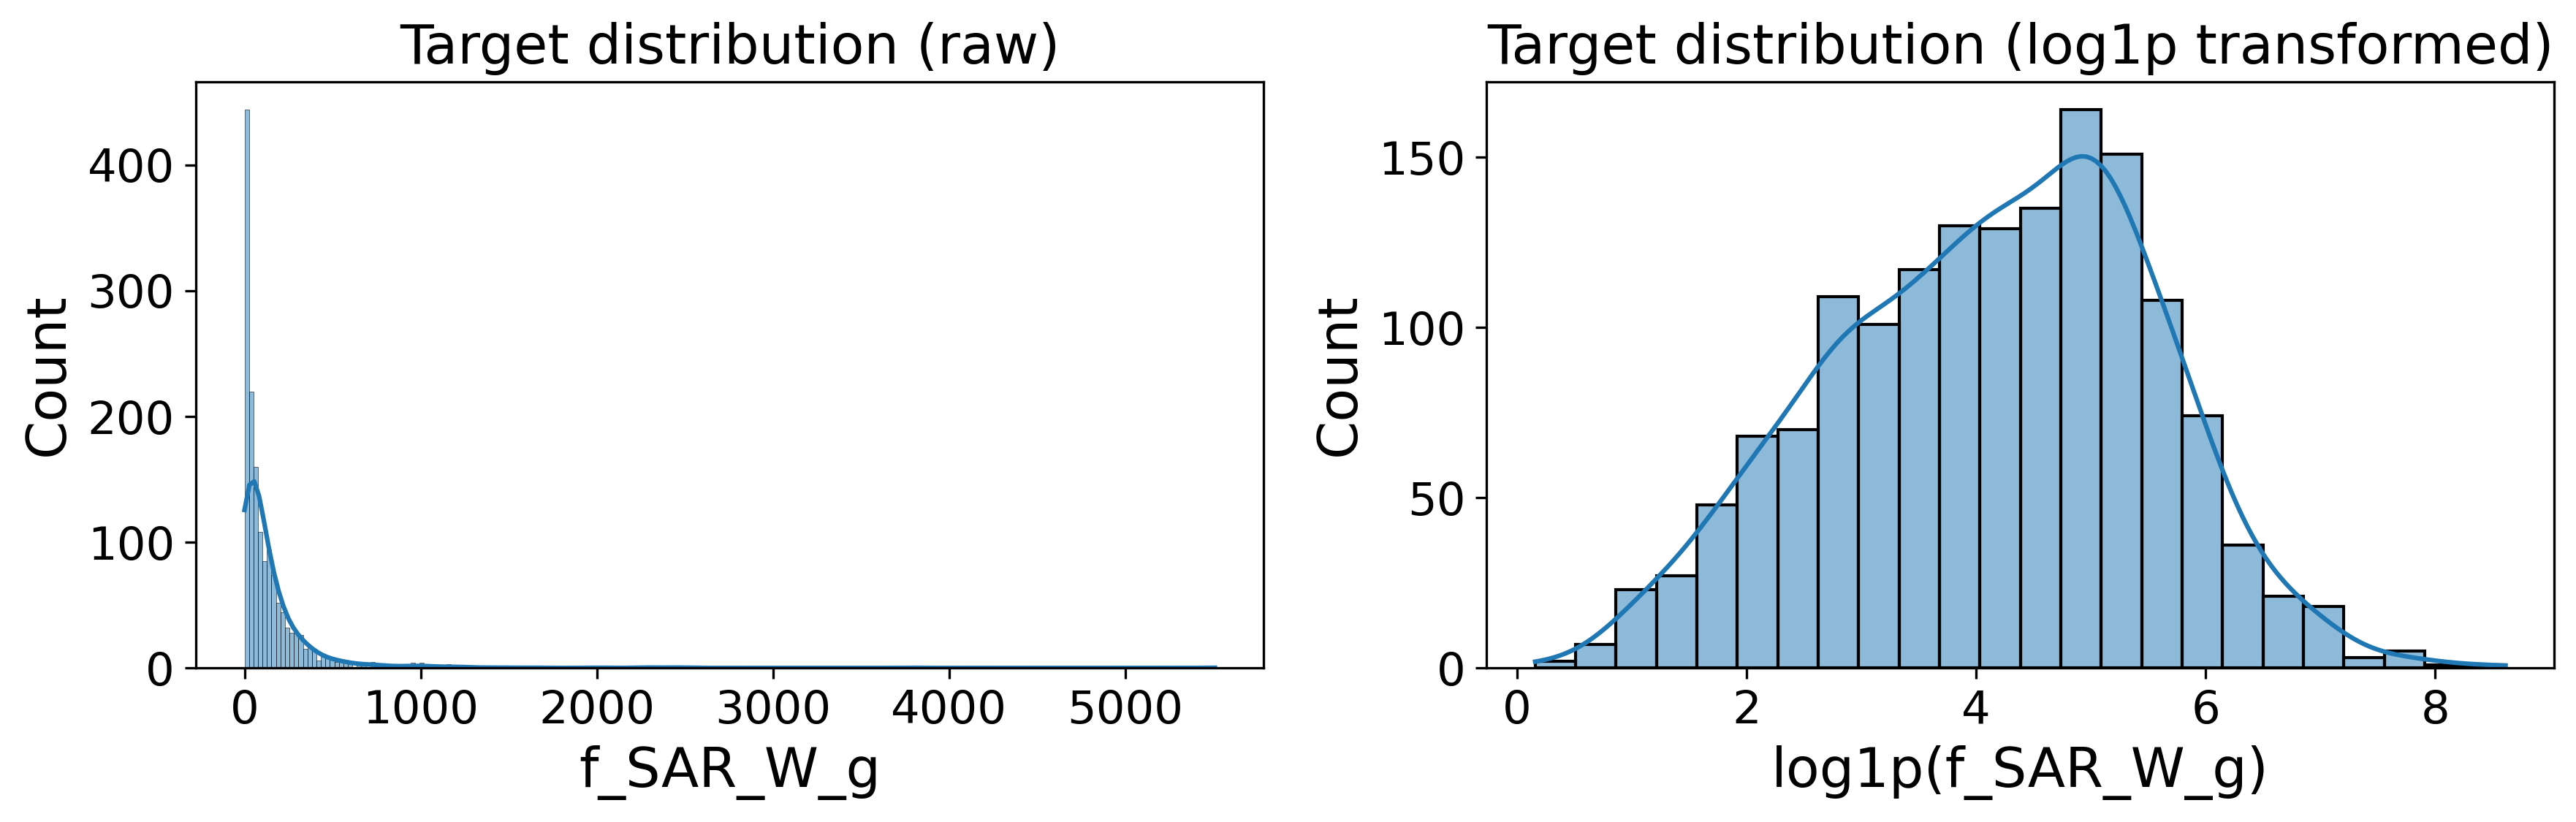

count    1548.000000
mean      146.395010
std       277.814976
min         0.170000
25%        20.900000
50%        67.520000
75%       169.010000
max      5510.000000
Name: f_SAR_W_g, dtype: float64


In [43]:
# --- 3c. Target distribution ---
target_col = TARGET_COL.replace('\ufeff', '').replace('\u200b', '').strip()
y_raw = df[target_col]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_raw, kde=True, ax=axes[0])
axes[0].set_title('Target distribution (raw)')
axes[0].set_xlabel(target_col)

sns.histplot(np.log1p(y_raw), kde=True, ax=axes[1])
axes[1].set_title('Target distribution (log1p transformed)')
axes[1].set_xlabel(f'log1p({target_col})')
plt.tight_layout()
plt.savefig('Distribution.svg', dpi=800,bbox_inches = 'tight')
plt.show()


print(y_raw.describe())

In [44]:
# --- 3d. Categorical column cardinality ---
for col in CAT_COLS:
    if col in df.columns:
        print(f"\n{col} ({df[col].nunique()} unique values):")
        print(df[col].value_counts(dropna=False).head(10))


c_shape_type (7 unique values):
c_shape_type
spherical         1167
NaN                170
nano_cube           83
octahedron          52
nano_flower         24
irregular           23
aggregate           18
semi_spherical      11
Name: count, dtype: int64

c_magnetic_phase (7 unique values):
c_magnetic_phase
superparamagnetic     1068
ferrimagnetic          217
NaN                    141
ferromagnetic           84
soft ferrimagnetic      22
soft ferromagnetic      13
Ferrimagnetic            2
paramagnetic             1
Name: count, dtype: int64

c_coating (122 unique values):
c_coating
NaN                                      444
none                                     137
PEG                                       82
protonated hydroxyl group due to pH 4     77
Oleic acid                                67
Citric acid                               66
Chitosan                                  62
oleic acid                                38
PVP                                       33
o

In [45]:
# --- 3e. Numeric feature correlations with target ---
numeric_df = df.select_dtypes(include=np.number)
if TARGET_COL in numeric_df.columns:
    corr = numeric_df.corr()[TARGET_COL].drop(TARGET_COL).sort_values(key=abs, ascending=False)
    print("Top correlations with target:")
    print(corr)

Top correlations with target:
f_Ms_emu_g_MNP                 0.309831
f_avg_core_width_nm            0.212310
f_area_volume_ratio           -0.157436
f_area_core_estimated_nm2      0.153174
f_H_Oe                         0.139183
f_FCY_kHz                      0.130932
Ca_comp                        0.108651
f_volume_core_estimated_nm3    0.108263
f_conc_MNP_mg_mL              -0.103827
S. No.                        -0.102738
f_is_inorganic                -0.071056
Cu_comp                        0.066102
f_is_organic                   0.053601
Tb_comp                        0.045630
f_Hc_Oe                       -0.041595
Mg_comp                       -0.037980
f_is_composite_coating         0.037516
Ga_comp                       -0.033765
Nd_comp                       -0.031919
Ni_comp                       -0.030614
Mn_comp                        0.029041
f_avg_core_sd_nm _BOTH        -0.025636
Sn_comp                       -0.024635
Co_comp                       -0.020375
f_is_coate

---
## 4. Train / Val / Test Split

Split **before** any preprocessing. The test set is locked away and never used to fit transformers or make tuning decisions. All imputers, encoders, and scalers are fit on `x_train` only.

In [46]:
# cutoff_threshold = df['f_SAR_W_g'].quantile(0.90)

# filtered_df = df[df['f_SAR_W_g'] <= cutoff_threshold]

# top_performers_df = df[df['f_SAR_W_g'] > cutoff_threshold]

# top_performers_df.to_excel("top_existing_performers.xlsx")
# df = filtered_df

In [47]:
target_col = TARGET_COL.replace('\ufeff', '').replace('\u200b', '').strip()
X = df.drop(columns=[target_col])
y = df[target_col]

# # 80 / 10 / 10 split
x_train, x_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

# groups = X['DOI']

# gss_test = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
# train_val_idx, test_idx = next(gss_test.split(X, y, groups=groups))

# x_train_val = X.iloc[train_val_idx]
# y_train_val = y.iloc[train_val_idx]
# groups_train_val = groups.iloc[train_val_idx]

# x_test = X.iloc[test_idx]
# y_test = y.iloc[test_idx]

# gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
# train_idx, val_idx = next(gss_val.split(x_train_val, y_train_val, groups=groups_train_val))

# x_train = x_train_val.iloc[train_idx]
# y_train = y_train_val.iloc[train_idx]

# x_val = x_train_val.iloc[val_idx]
# y_val = y_train_val.iloc[val_idx]

x_train.drop(['DOI'], axis=1, inplace=True)
x_val.drop(['DOI'], axis=1, inplace=True)
x_test.drop(['DOI'], axis=1, inplace=True)

print(f"Train : {x_train.shape[0]} rows")
print(f"Val   : {x_val.shape[0]} rows")
print(f"Test  : {x_test.shape[0]} rows  ← locked until final evaluation")

Train : 1238 rows
Val   : 155 rows
Test  : 155 rows  ← locked until final evaluation


---
## 5. Preprocessing

All transformers are **fit on `x_train` only**, then applied to val and test.

Steps:
1. Engineer binary indicator flags from categorical columns
2. Fill categorical NaNs and ordinal-encode
3. Impute remaining numeric missing values (IterativeImputer)
4. Log-transform the target (right-skewed regression target)

In [48]:
# --- 5a. Binary presence indicators (fit-free, safe to apply before split logic) ---
def add_presence_flags(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()
    df_out['f_is_coated']  = df_out['c_coating'].notna().astype(int)
    df_out['f_is_shaped']  = df_out['c_shape_type'].notna().astype(int)
    df_out['f_is_phased']  = df_out['c_magnetic_phase'].notna().astype(int)
    return df_out

x_train = add_presence_flags(x_train)
x_val   = add_presence_flags(x_val)
x_test  = add_presence_flags(x_test)

In [49]:
# --- 5b. Categorical encoding ---
# Fill NaN → 'Unknown' for unseen categories, then ordinal-encode.
# Where the presence flag == 0 (field was missing), force the encoded value to -1.
# Encoders are fit on train only.

def encode_categorical(train_df, val_df, test_df, cat_col, flag_col):
    for df_part in [train_df, val_df, test_df]:
        df_part[cat_col] = df_part[cat_col].fillna('Unknown').astype(str)

    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    train_df[cat_col] = enc.fit_transform(train_df[[cat_col]])
    val_df[cat_col]   = enc.transform(val_df[[cat_col]])
    test_df[cat_col]  = enc.transform(test_df[[cat_col]])

    for df_part in [train_df, val_df, test_df]:
        df_part.loc[df_part[flag_col] == 0, cat_col] = -1
        df_part.drop(columns=[flag_col], inplace=True)

    return train_df, val_df, test_df

x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_coating',       'f_is_coated')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_shape_type',    'f_is_shaped')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_magnetic_phase', 'f_is_phased')

print("Encoding done. x_train shape:", x_train.shape)

Encoding done. x_train shape: (1238, 31)


In [50]:
# --- 5c. Numeric imputation (fit on train only) ---
numeric_cols = x_train.select_dtypes(include=np.number).columns.tolist()

imputer = MissForest(rgr=RandomForestRegressor(n_estimators=100,random_state=62),max_iter=10)

if x_train[numeric_cols].isnull().any().any():
    x_train[numeric_cols] = imputer.fit_transform(x_train[numeric_cols])
    x_val[numeric_cols]   = imputer.transform(x_val[numeric_cols])
    x_test[numeric_cols]  = imputer.transform(x_test[numeric_cols])
    print("Imputation applied.")
else:
    print("No missing values in numeric columns — skipping imputation.")

/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:333: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
 30%|███       | 3/10 [01:09<02:44, 23.46s/it]/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:303: UserWarning: NRMSE increased.
  warnings.warn("NRMSE increased.")
/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:453: UserWarning: Stopping criterion triggered during fitting. Before last imputation matrix will be returned.
  warnings.warn(
 30%|███       | 3/10 [01:32<03:36, 30.94s/it]
/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:490: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
/usr/local/lib/python3.13/dist

Imputation applied.


---
## 6. Feature Engineering

Domain-informed composite features, then quantile-normalise all inputs (fit on train only).

In [51]:
# --- 6a. Feature scaling (QuantileTransformer, fit on train only) ---
transf = QuantileTransformer(random_state=RANDOM_STATE)

x_train_scaled = transf.fit_transform(x_train)
x_val_scaled   = transf.transform(x_val)
x_test_scaled  = transf.transform(x_test)

print("Scaling done. Train shape:", x_train_scaled.shape)

Scaling done. Train shape: (1238, 31)


In [52]:
# --- 6b. Log transformation ---
y_train_log = np.log1p(y_train.values.astype(float))   # log1p on raw SAR
y_val_log   = np.log1p(y_val.values.astype(float))
y_test_log  = np.log1p(y_test.values.astype(float))

scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train_log.reshape(-1, 1)).flatten()
y_val_scaled   = scaler.transform(y_val_log.reshape(-1, 1)).flatten()
y_test_scaled  = scaler.transform(y_test_log.reshape(-1, 1)).flatten()

print("=== Scaler sanity check ===")
print(f"  data_min_ : {scaler.data_min_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_min_[0]):.2f} W/g)")
print(f"  data_max_ : {scaler.data_max_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_max_[0]):.2f} W/g)")
assert scaler.data_max_[0] > 1.0, \
    "Scaler data_max_ is still wrong — y_train may still be pre-transformed. Restart kernel and rerun top-to-bottom."

# Use these as your targets for model training (rename to match rest of notebook)
y_train = y_train_scaled
y_val   = y_val_scaled
y_test  = y_test_scaled


=== Scaler sanity check ===
  data_min_ : 0.1570  (= log1p(0.17 W/g)
  data_max_ : 8.6145  (= log1p(5510.00 W/g)


---
## 7. Model Training

TabPFN is a prior-fitted Bayesian neural network — it doesn't need hyperparameter search but does require a valid API token for datasets above the default size limit.

In [53]:
# Set your TabPFN token (replace with your own from tabpfn.com)
X=pd.DataFrame(x_train_scaled,columns=x_train.columns,index=x_train.index)
y=pd.Series(y_train,index=x_train.index)

os.environ["TABPFN_TOKEN"] = "tabpfn_sk_BecwqtbAqmCwLDoMt4sRrFZSFeaGvrnxjjfoWQi9AiY"
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"

model = TabPFNRegressor(ignore_pretraining_limits=True)
model.fit(X,y)

print("Model trained.")

Model trained.


---
## 8. Evaluation

Evaluate on **val** (for monitoring/tuning feedback) and **test** (final unbiased estimate). Test metrics are read once — do not loop back and re-tune based on them.

In [54]:
x_val_scaled_df = pd.DataFrame(x_val_scaled, columns=x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns=x_train.columns)

y_val_pred  =  model.predict(x_val_scaled_df)
y_test_pred =  model.predict(x_test_scaled_df)
# Summary metrics
val_r2   = r2_score(y_val,  y_val_pred)
test_r2  = r2_score(y_test, y_test_pred)
val_rmse = np.sqrt(mean_squared_error(y_val,  y_val_pred))
test_rmse= np.sqrt(mean_squared_error(y_test, y_test_pred))

def inverse_sar(y_scaled: np.ndarray, fitted_scaler: MinMaxScaler) -> np.ndarray:
  y_scaled_clipped = np.clip(y_scaled, 0.0, 1.0)
  pred_log_units      = fitted_scaler.inverse_transform(y_scaled_clipped.reshape(-1, 1)).flatten()
  true_predicted_sar  = np.expm1(pred_log_units)
  return true_predicted_sar

y_test=inverse_sar(y_test,scaler)
y_test_pred=inverse_sar(y_test_pred,scaler)
err_90 = np.quantile(np.abs(y_test - y_test_pred), 0.90)

print(f"Validation  — R²: {val_r2:.4f}   RMSE: {val_rmse:.4f}")
print(f"Test        — R²: {test_r2:.4f}   RMSE: {test_rmse:.4f}")
print(f"90th-pct prediction error (test): ±{err_90:.4f}")

Validation  — R²: 0.8059   RMSE: 0.0738
Test        — R²: 0.8679   RMSE: 0.0580
90th-pct prediction error (test): ±81.4267


In [55]:
plt.rcParams.update({
    'figure.dpi': 300,          # High resolution for on-screen display
    'savefig.dpi': 800,         # High resolution for saved files
    'font.size': 15,            # Base font size
    'axes.titlesize': 18,       # Plot title size
    'axes.labelsize': 18,       # X and Y axis label size
    'xtick.labelsize': 15,      # X tick size
    'ytick.labelsize': 15,      # Y tick size
    'legend.fontsize': 15       # Legend text size
})

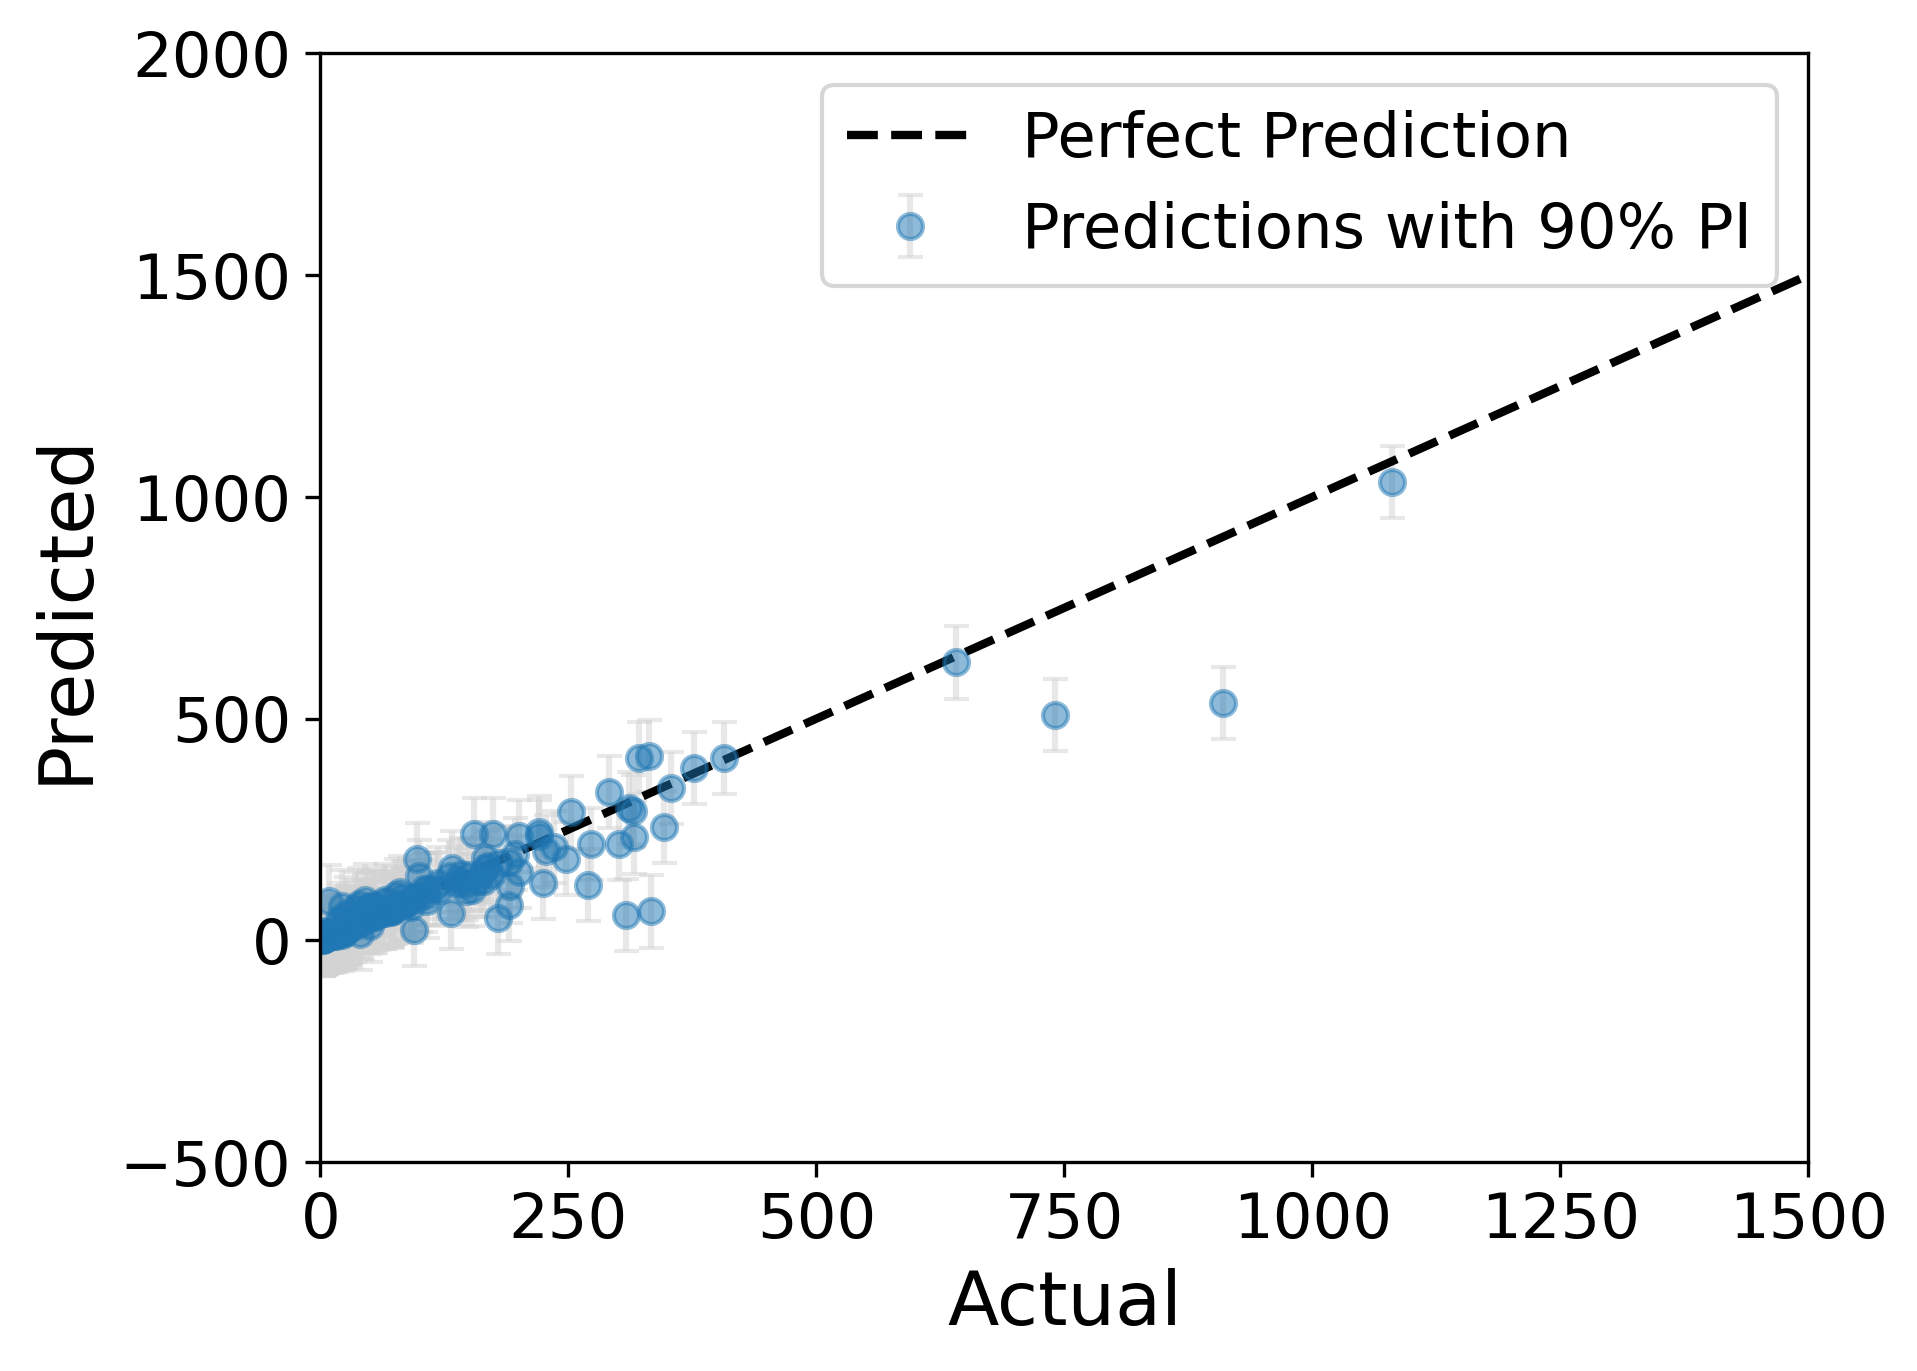

In [56]:
plt.errorbar(y_test,y_test_pred, yerr=err_90, fmt='o', alpha=0.5, ecolor='lightgray', capsize=3, label='Predictions with 90% PI')
plt.plot([0, 1500], [0, 1500], 'k--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.xlim([0, 1500])
plt.ylim([-500, 2000])
plt.savefig('actual_vs_predicted_PI.svg', dpi=800,bbox_inches = 'tight')
plt.show()

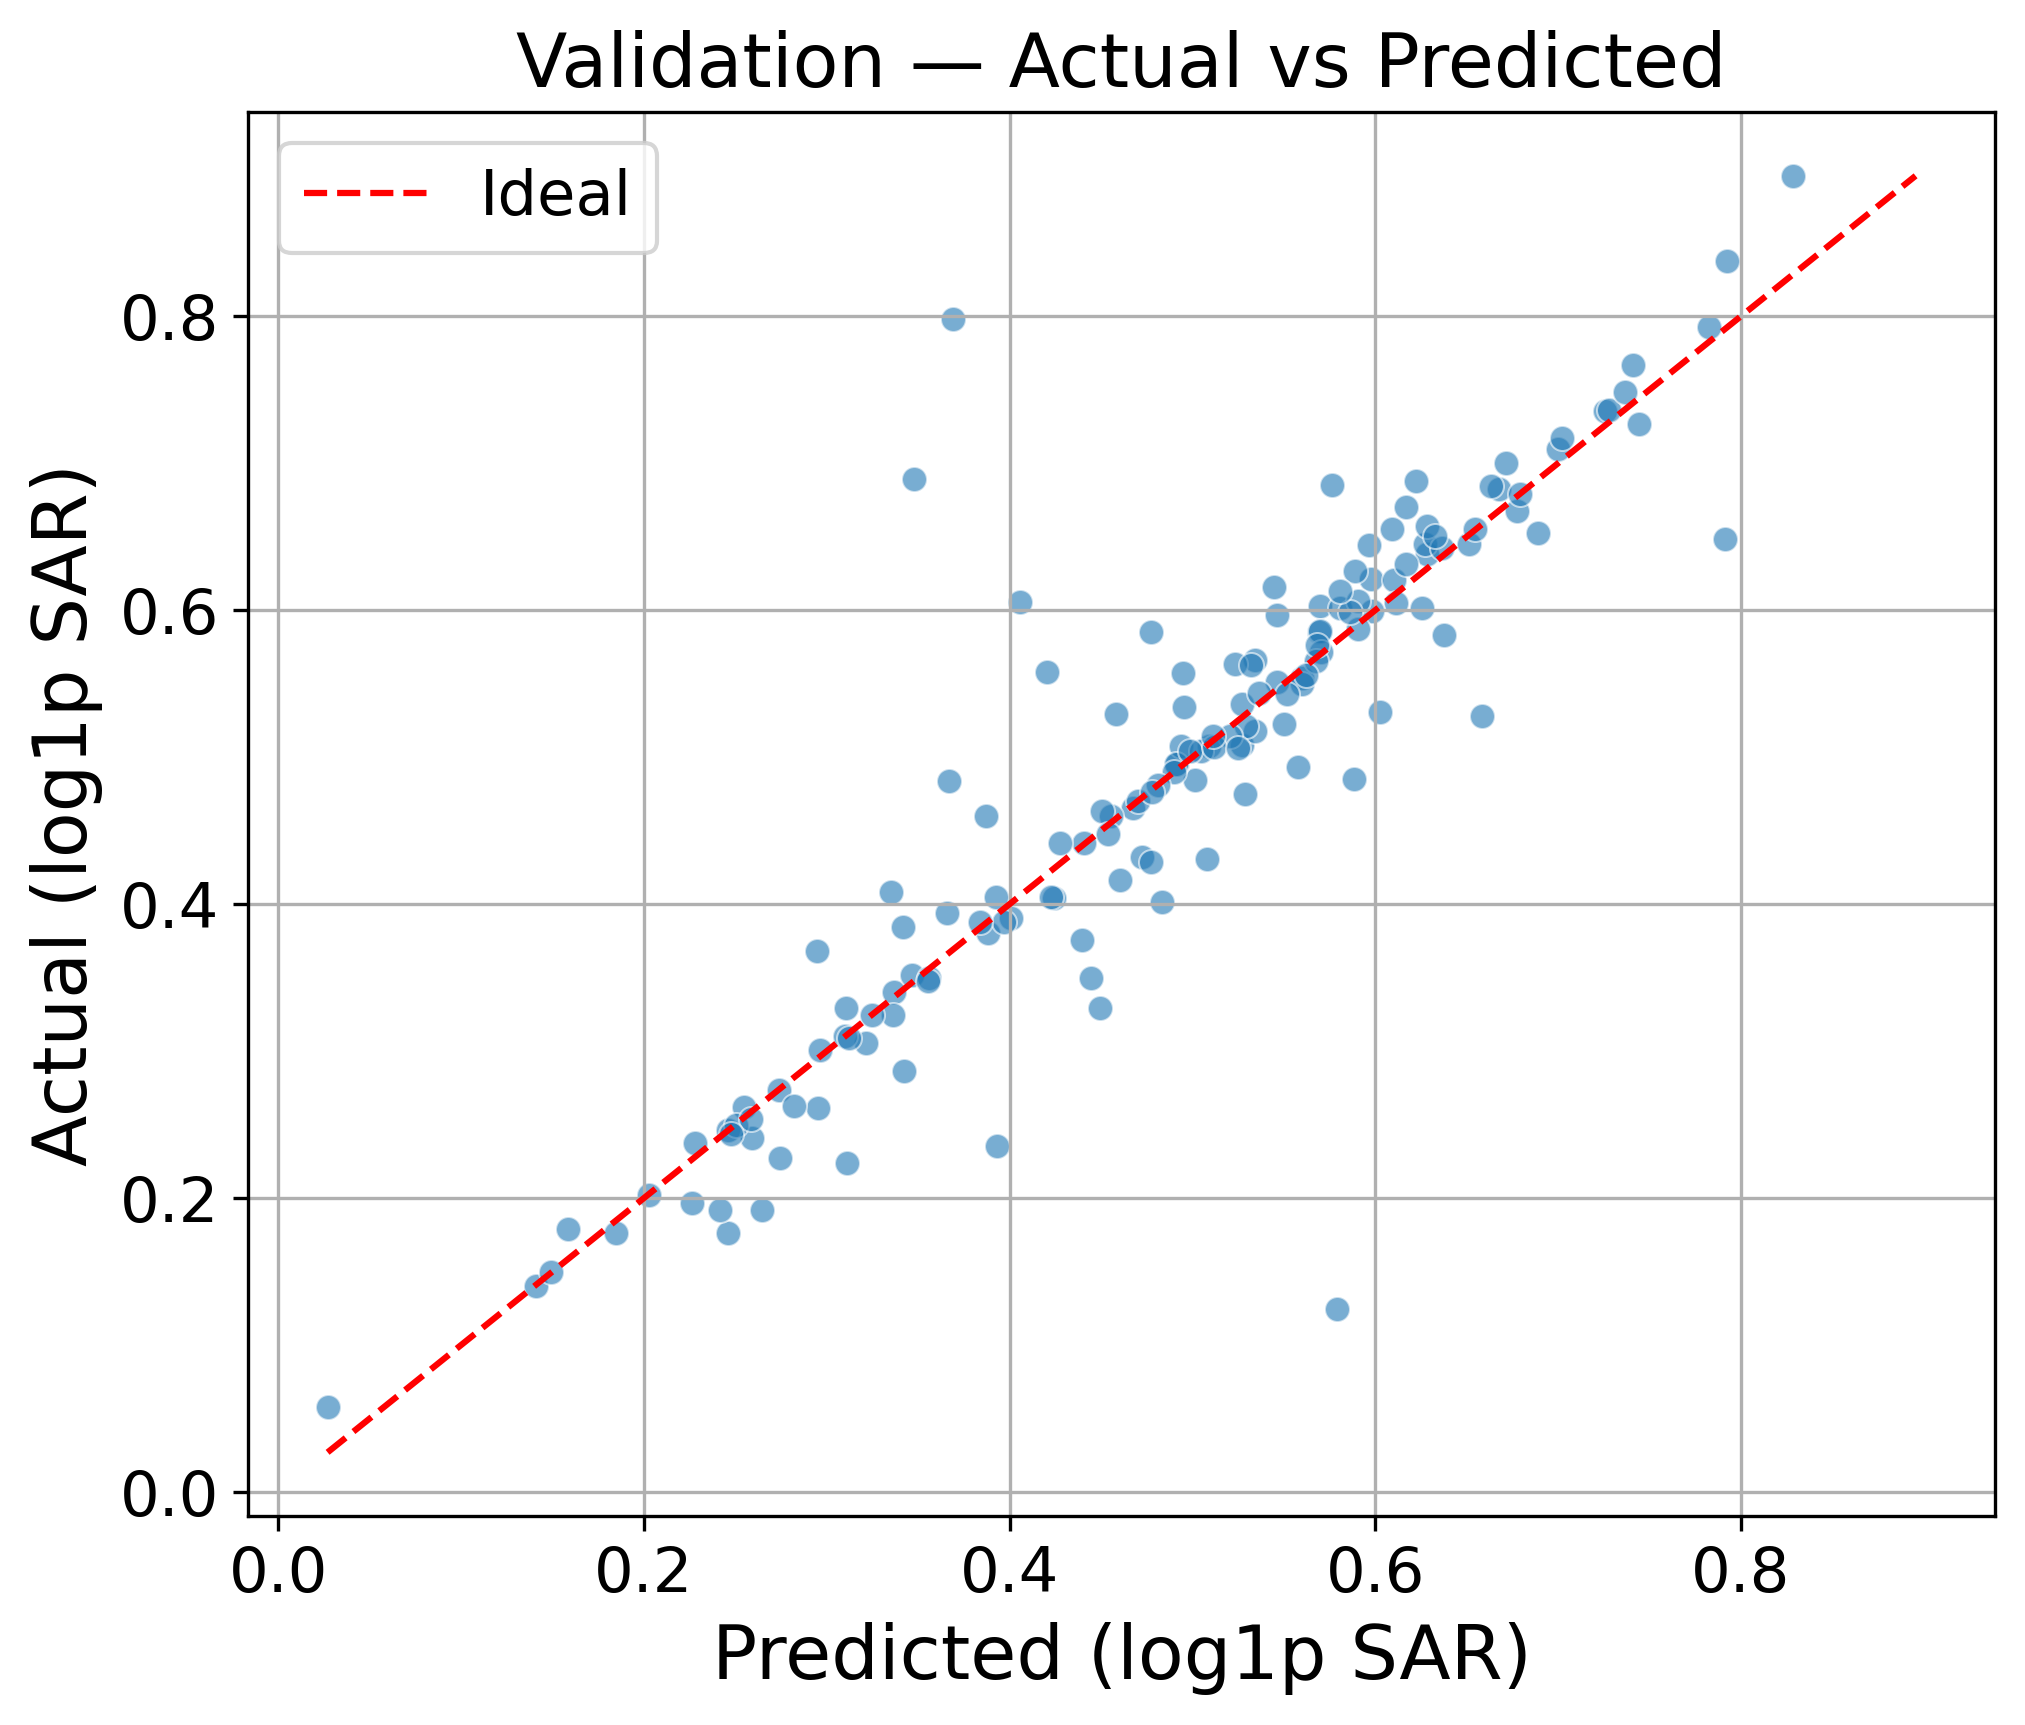

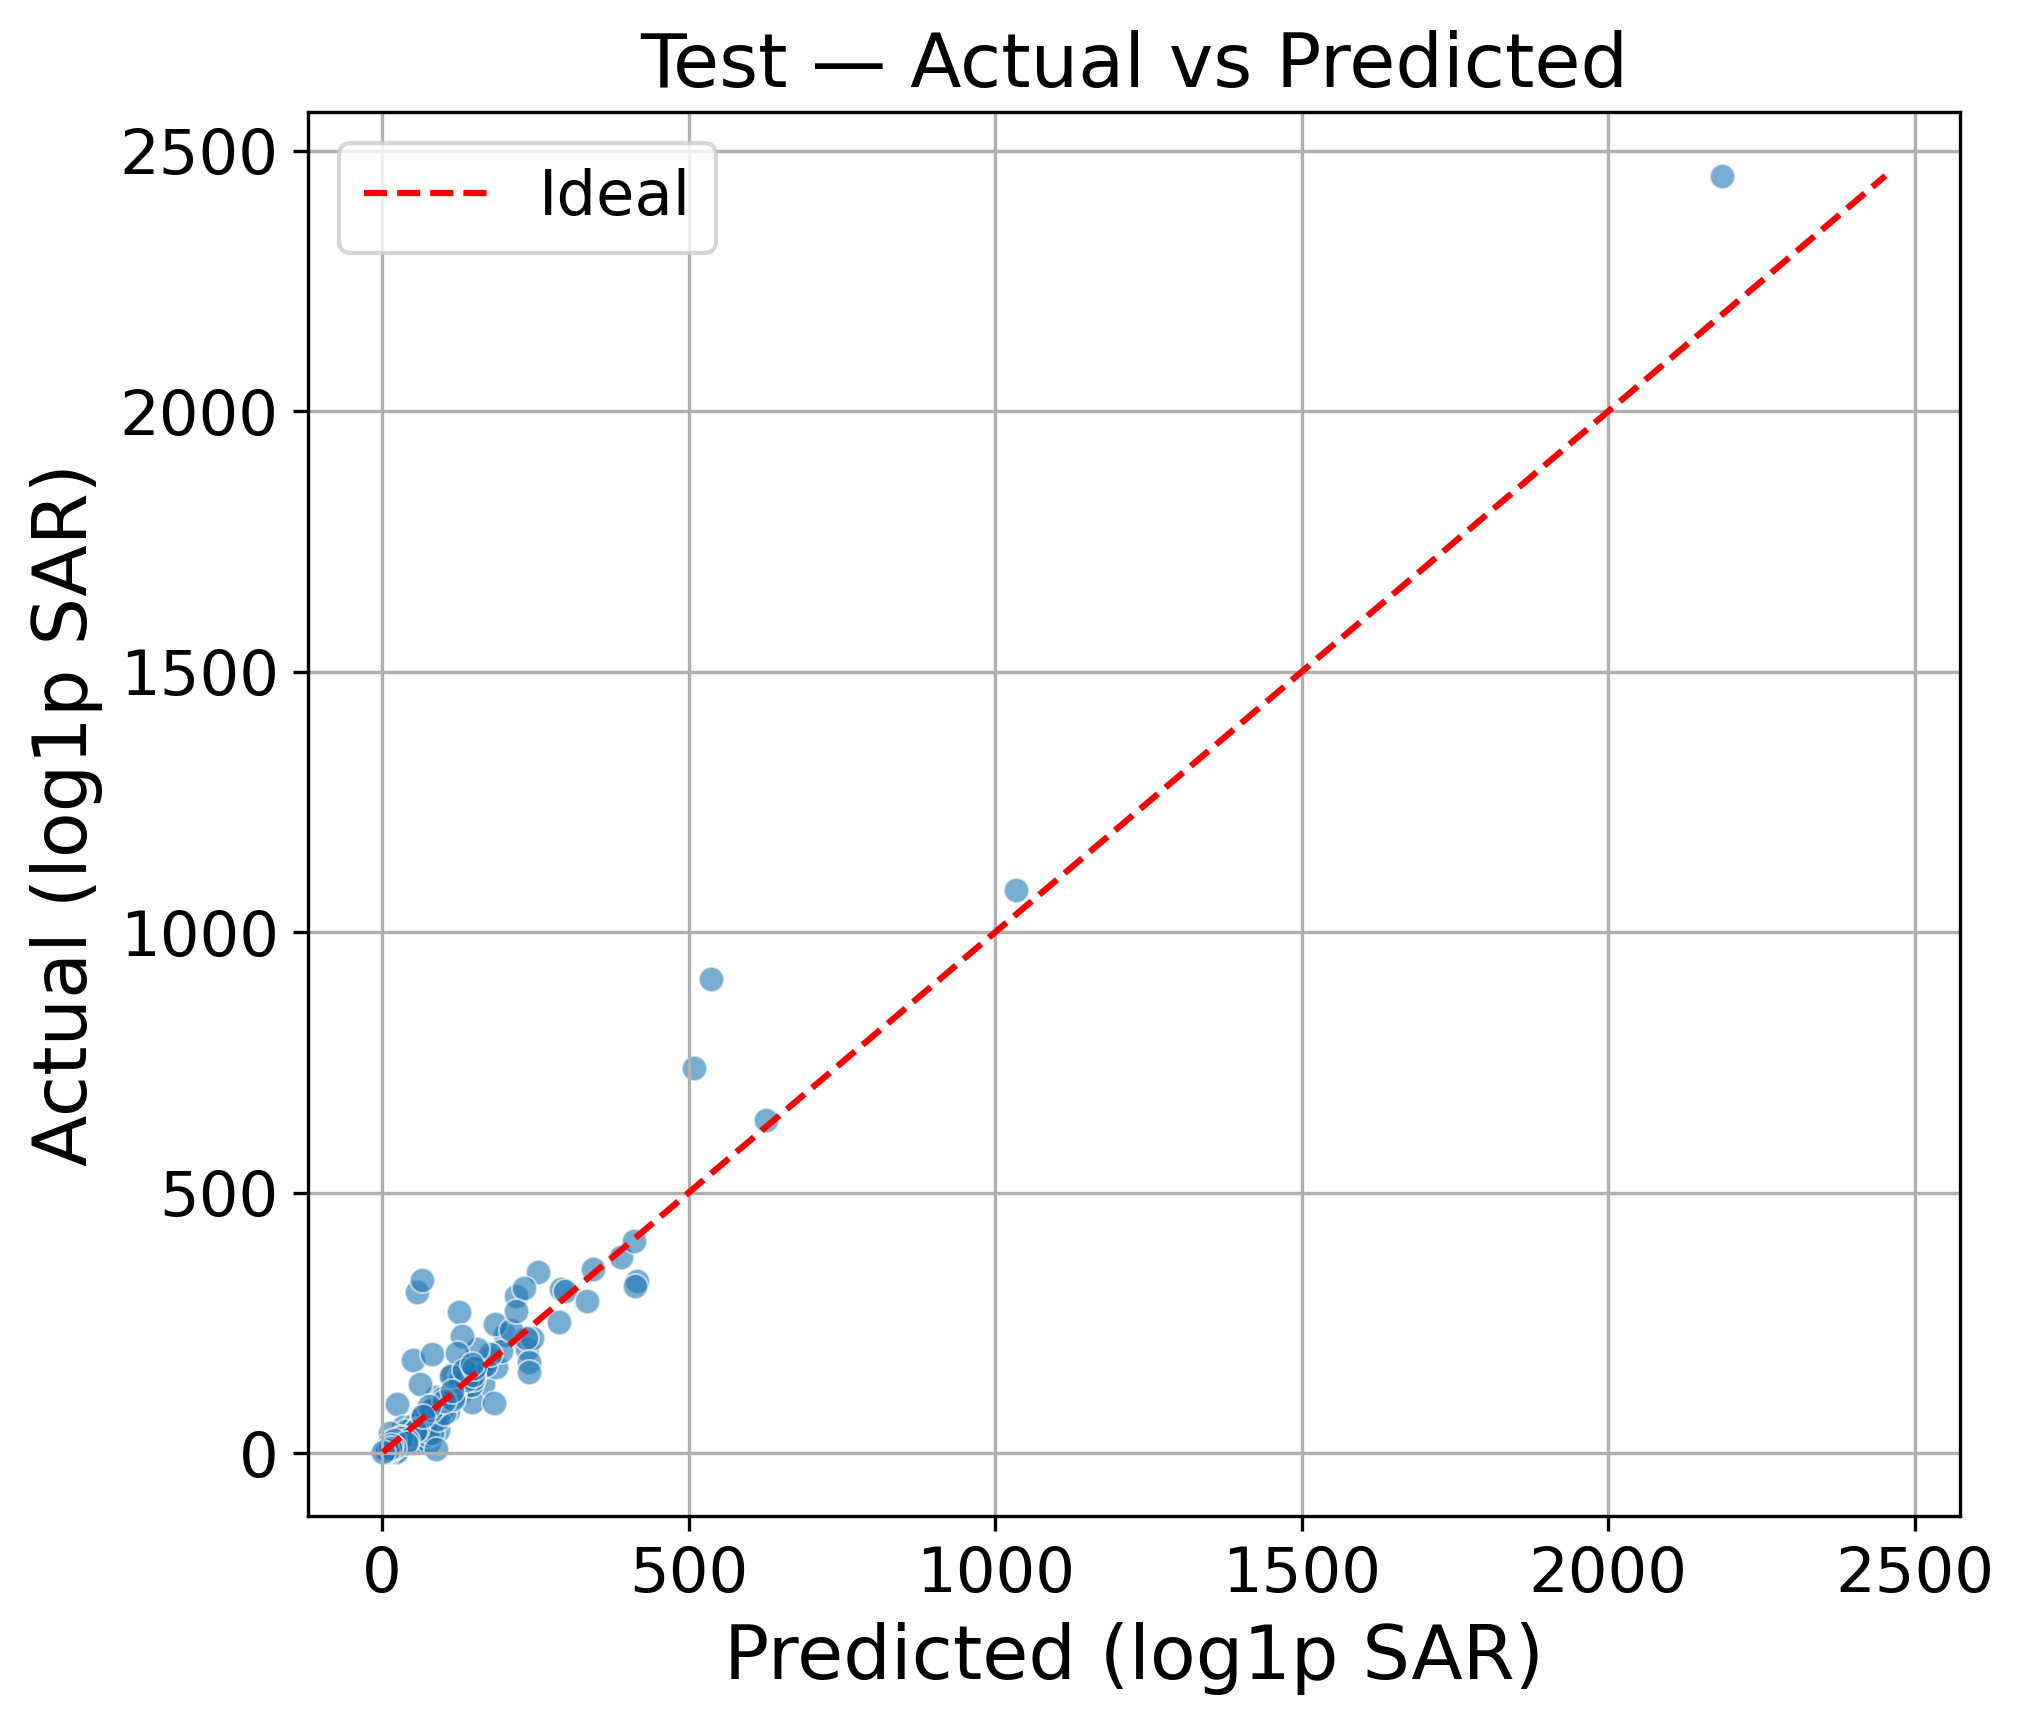

In [57]:
# --- 8b. Actual vs Predicted ---
def plot_actual_vs_predicted(y_true, y_pred, title):
    plt.figure(figsize=(7, 6))
    sns.scatterplot(x=y_pred, y=y_true, alpha=0.6)
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    plt.plot([lo, hi], [lo, hi], 'r--', label='Ideal')
    plt.title(title)
    plt.xlabel('Predicted (log1p SAR)')
    plt.ylabel('Actual (log1p SAR)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f'{title}.svg', dpi=800,bbox_inches='tight')
    plt.show()

plot_actual_vs_predicted(y_val,  y_val_pred,  'Validation — Actual vs Predicted')
plot_actual_vs_predicted(y_test, y_test_pred, 'Test — Actual vs Predicted')

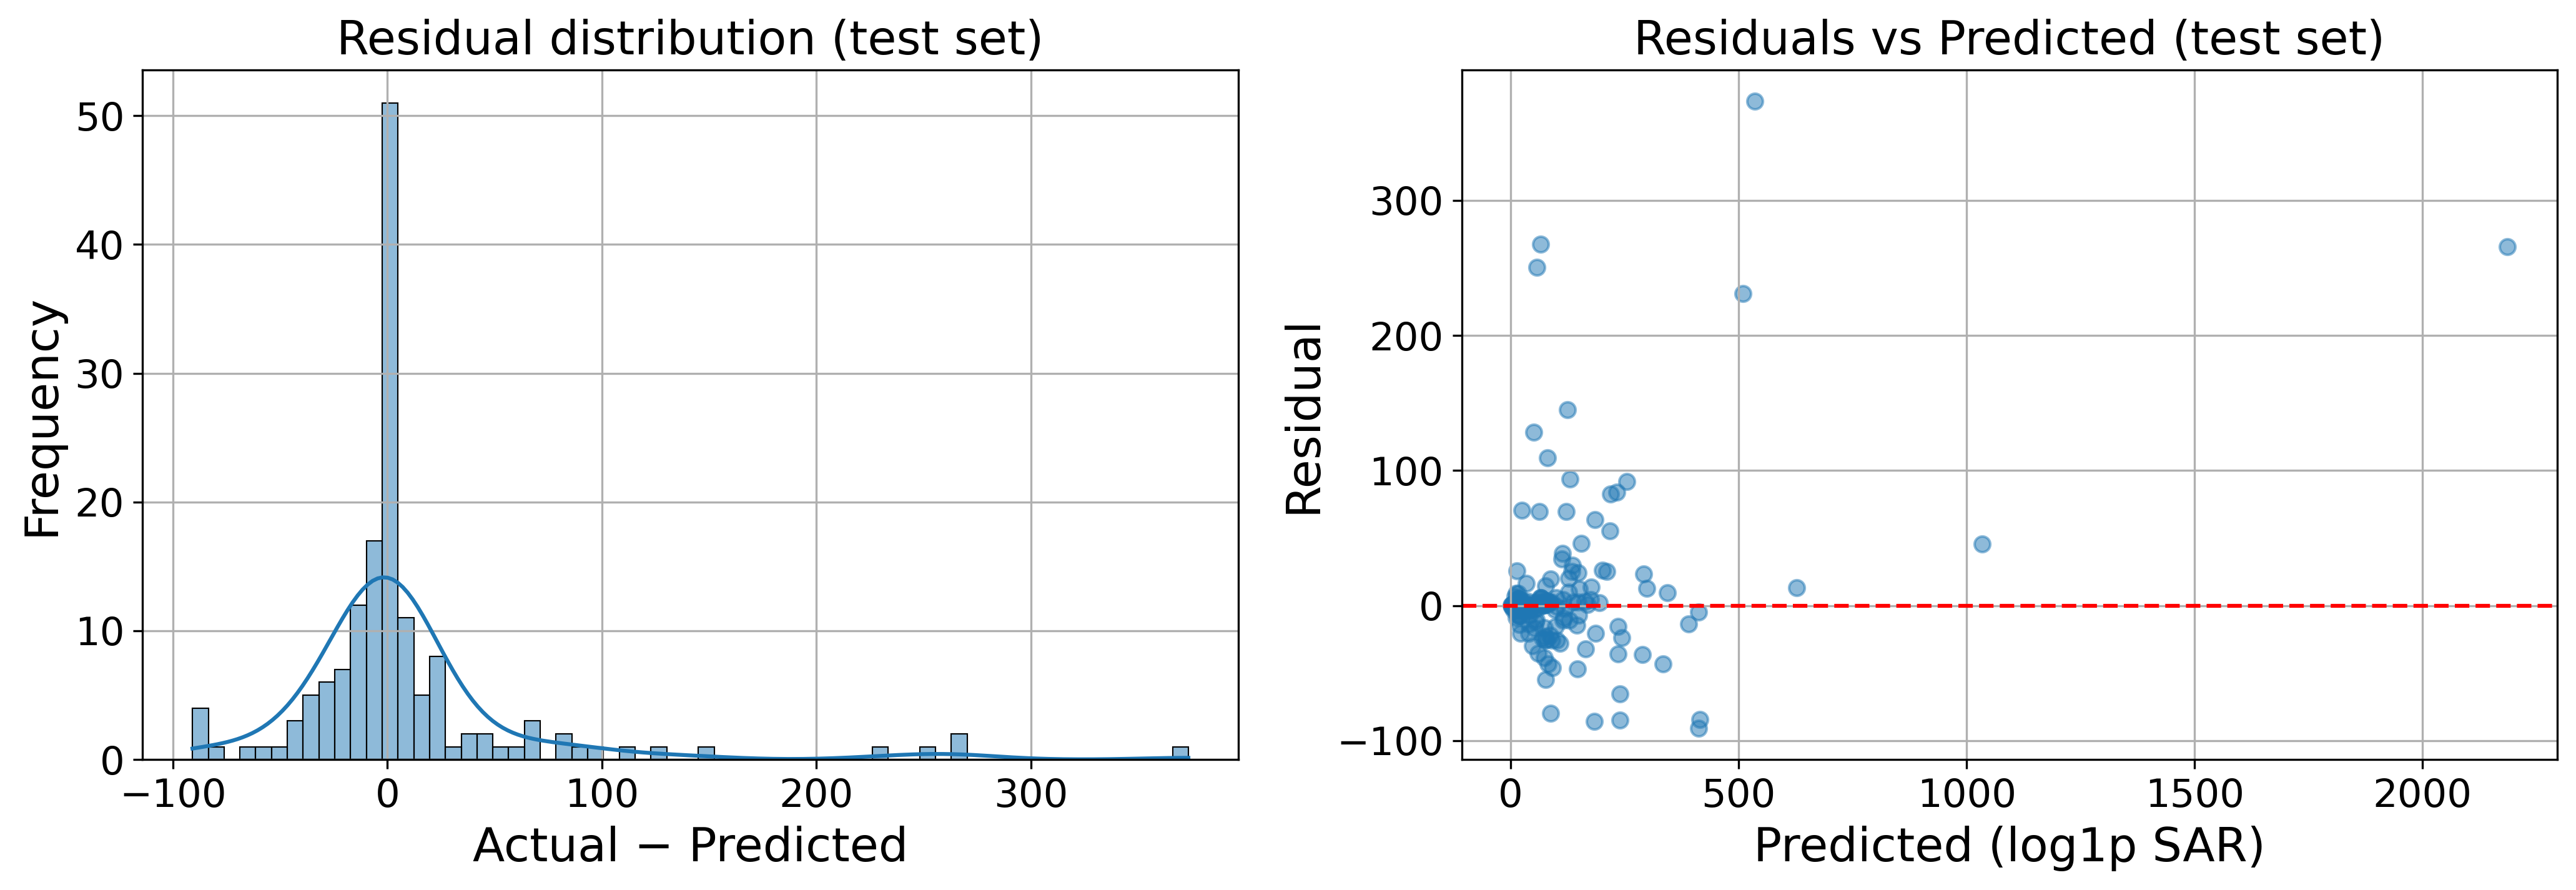

In [58]:
# --- 8c. Residual analysis ---
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title('Residual distribution (test set)')
axes[0].set_xlabel('Actual − Predicted')
axes[0].set_ylabel('Frequency')
axes[0].grid(True)

axes[1].scatter(y_test_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (test set)')
axes[1].set_xlabel('Predicted (log1p SAR)')
axes[1].set_ylabel('Residual')
axes[1].grid(True)
plt.tight_layout()
plt.savefig('Residuals.svg', dpi=800,bbox_inches = 'tight')
plt.show()

In [59]:
# SHAP Analysis using Kernel Explainer
background  = s.sample(x_train_scaled, 10)
explainer   = s.KernelExplainer(model.predict, background)
shap_values = explainer.shap_values(x_test_scaled)

shap_arr = shap_values[1] if isinstance(shap_values, list) else shap_values

imp_df = pd.DataFrame({
    'feature':    x_train.columns,
    'importance': np.abs(shap_arr).mean(axis=0),
}).sort_values('importance', ascending=False)

print("Feature importances (mean |SHAP|):")
print(imp_df.to_string(index=False))

  0%|          | 0/155 [00:00<?, ?it/s]

Feature importances (mean |SHAP|):
                    feature  importance
                  f_FCY_kHz    0.034027
             f_is_inorganic    0.030722
                    Mn_comp    0.027348
                    Mg_comp    0.018042
        f_avg_core_width_nm    0.015440
                     S. No.    0.008759
             f_Ms_emu_g_MNP    0.006177
                    Zn_comp    0.004741
                    Ni_comp    0.004234
                    Nd_comp    0.004124
                    Sn_comp    0.004050
                  c_coating    0.003980
     f_is_composite_coating    0.002964
           c_magnetic_phase    0.002169
  f_area_core_estimated_nm2    0.002119
                    Tb_comp    0.001978
               f_is_organic    0.001165
                     f_H_Oe    0.000831
               c_shape_type    0.000718
                   is_doped    0.000675
                    Co_comp    0.000673
                    Gd_comp    0.000434
        f_area_volume_ratio    0.000356
     

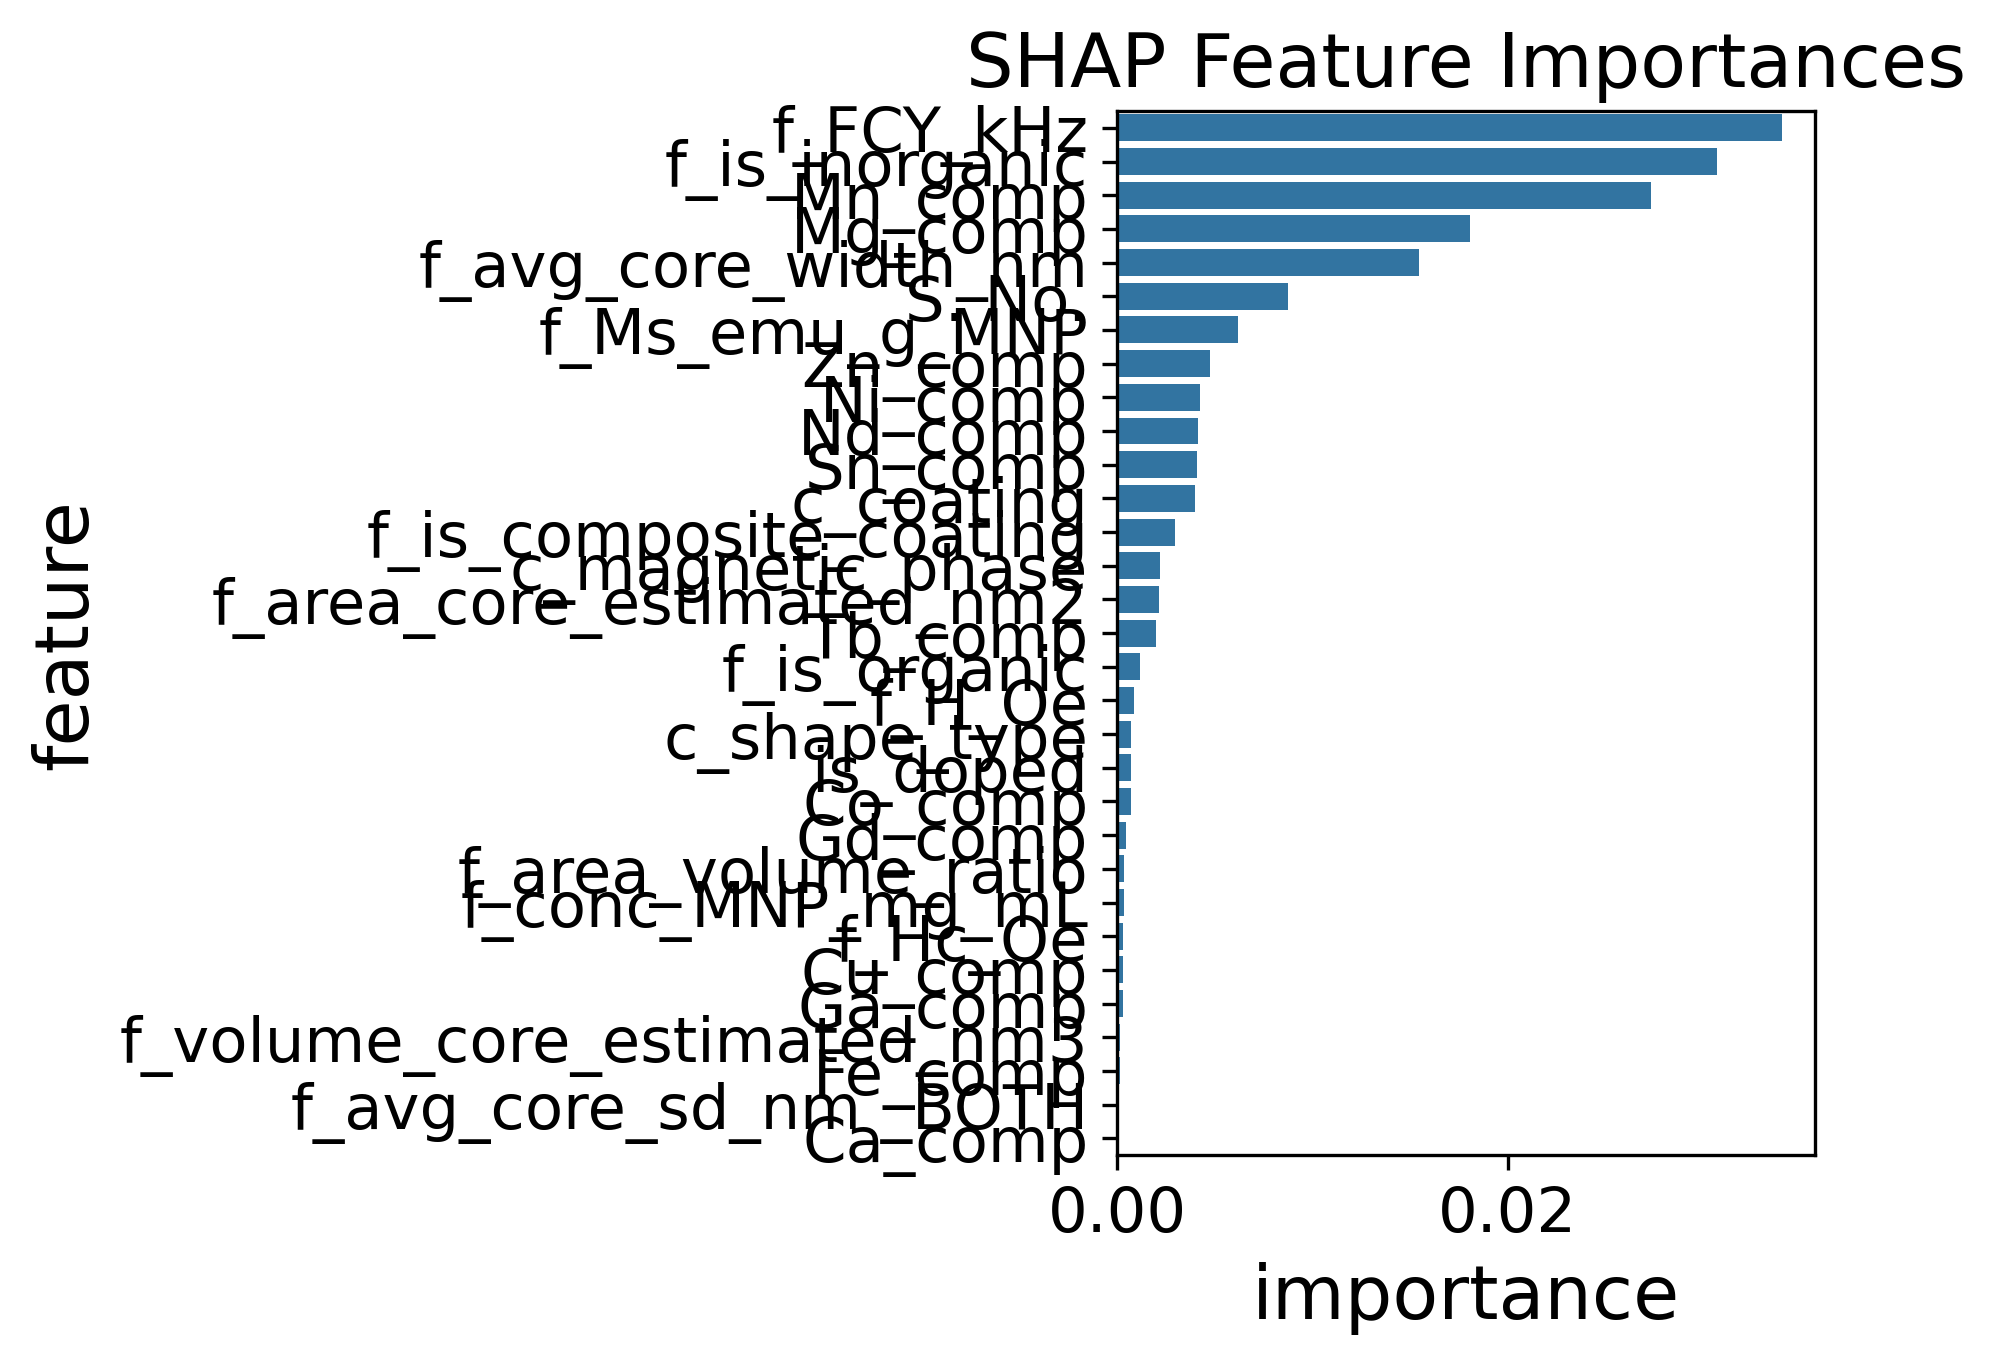

In [60]:
# SHAP summary plot
sns.barplot(imp_df, x='importance', y='feature', orient='h')
plt.title('SHAP Feature Importances')
plt.tight_layout()
plt.savefig('ShapSummary.svg', dpi=800)
plt.show()

In [61]:
features  = ['f_H_Oe', 'f_FCY_kHz', 'f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'is_doped']
dopant_cols  = [c for c in df.columns if c.endswith('_comp') and c != 'Fe_comp']
all_feats = features + dopant_cols

# Build an analysis dataframe from the training split only
train_df_raw = df.loc[x_train.index].copy()
train_df_raw[dopant_cols] = train_df_raw[dopant_cols].fillna(0)
train_df_raw['f_avg_core_width_nm'] = train_df_raw['f_avg_core_width_nm'].fillna(
    train_df_raw['f_avg_core_width_nm'].median())
train_df_raw = train_df_raw.dropna(subset=[target_col])

x = train_df_raw[all_feats]
y = train_df_raw[target_col]

train_df_raw['y_test_pred']= model.predict(x_train)

# LRT threshold classification
train_df_raw['H_kA_m']     = train_df_raw['f_H_Oe'] * 0.07958
train_df_raw['f_Hz']        = train_df_raw['f_FCY_kHz'] * 1000
train_df_raw['Hf_product']  = train_df_raw['H_kA_m'] * train_df_raw['f_Hz']
lrt_thresh = 5e6
train_df_raw['lrt'] = np.where(
    train_df_raw['Hf_product'] <= lrt_thresh, 'Low Field (LRT)', 'High Field')

train_df_raw['Freq_Range'] = pd.qcut(
    train_df_raw['f_FCY_kHz'], q=3, labels=['Low Freq', 'Mid Freq', 'High Freq'])

print(train_df_raw['lrt'].value_counts())

lrt
Low Field (LRT)    689
High Field         549
Name: count, dtype: int64


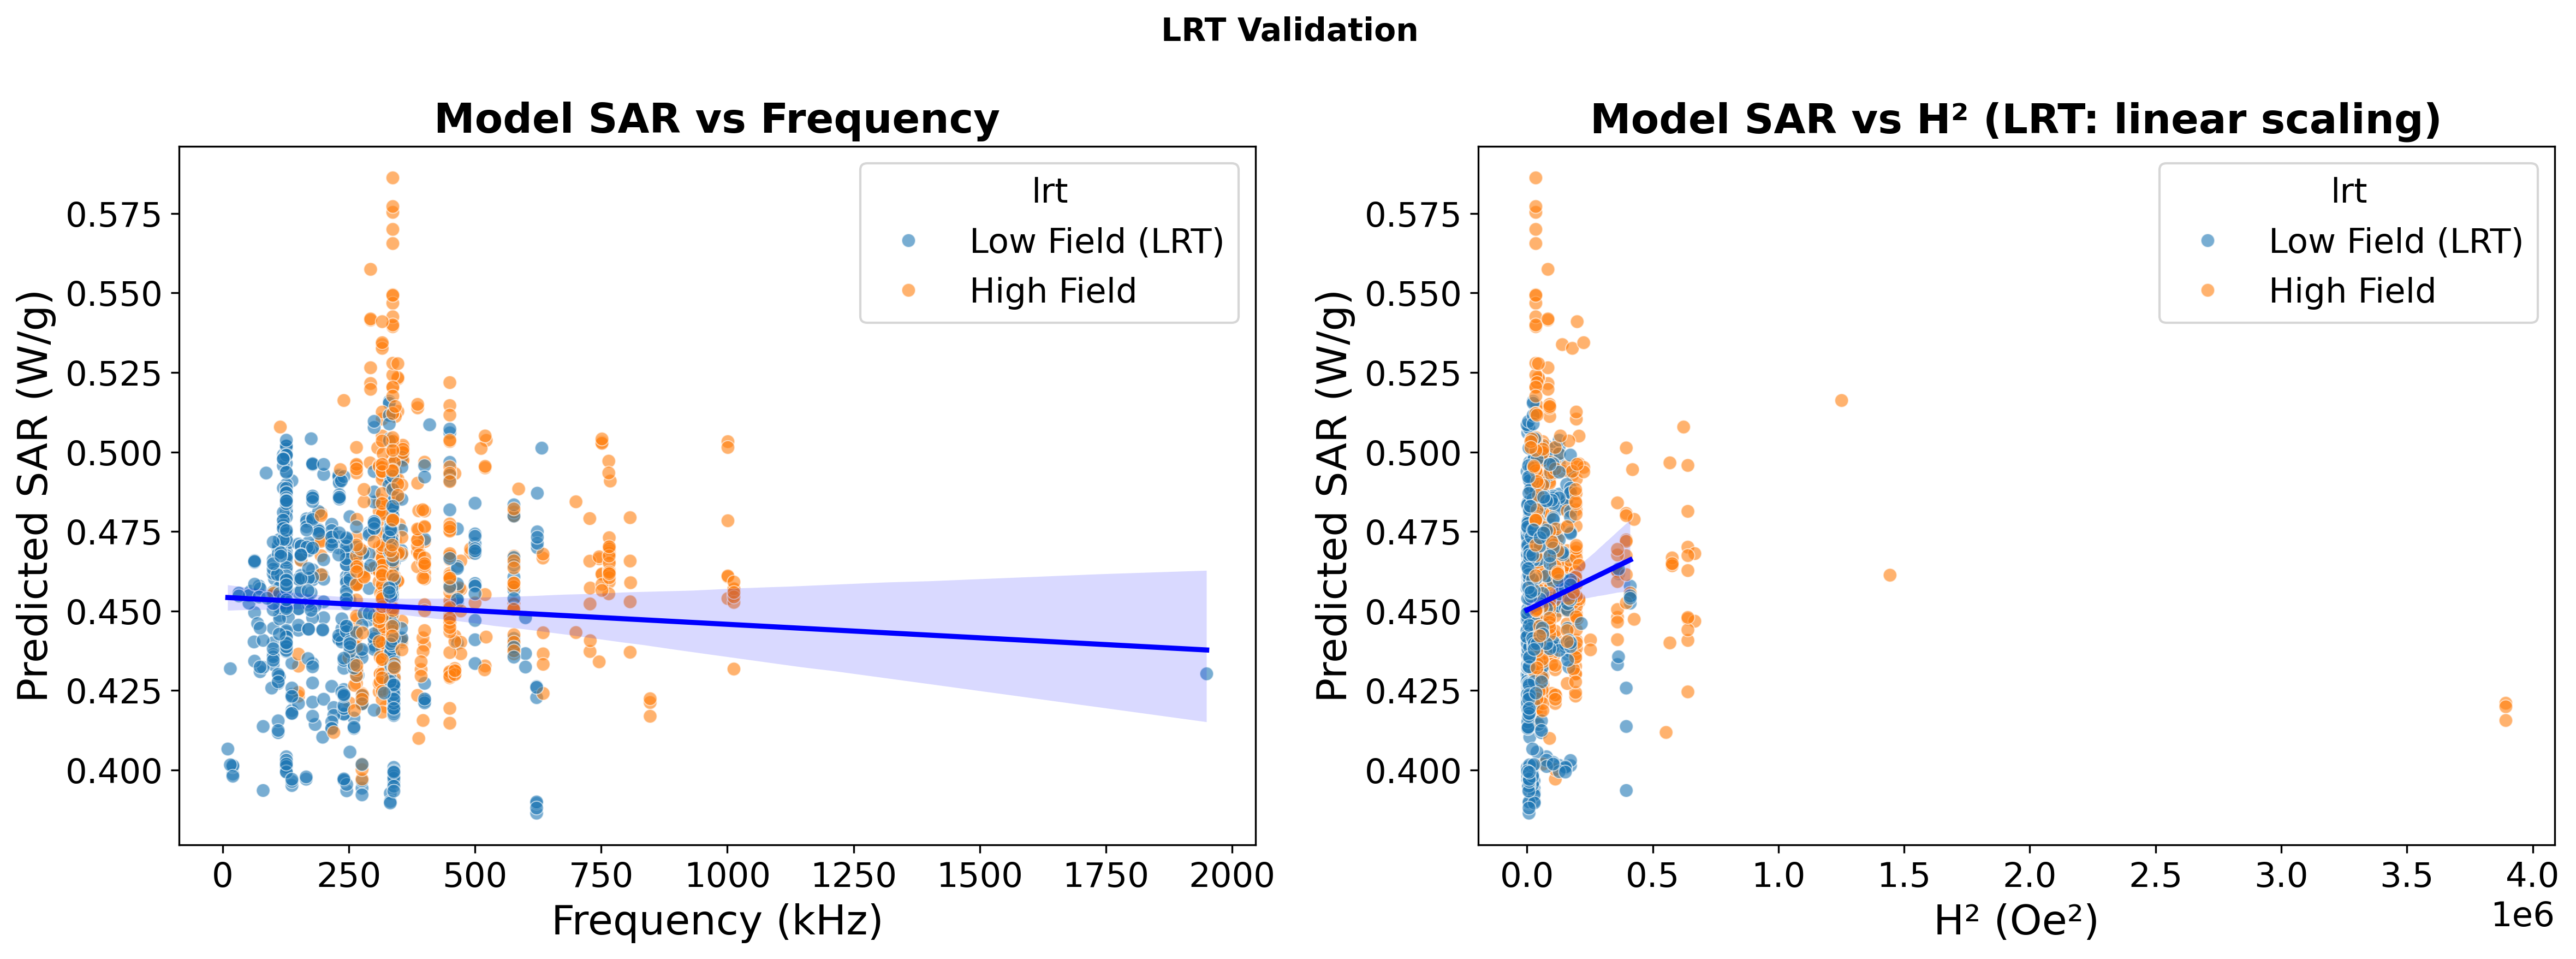

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# SAR vs Frequency
sns.scatterplot(data=train_df_raw, x='f_FCY_kHz', y='y_test_pred',
                hue='lrt', alpha=0.6, ax=axes[0])
sns.regplot(data=train_df_raw[train_df_raw['lrt'] == 'Low Field (LRT)'],
            x='f_FCY_kHz', y='y_test_pred',
            scatter=False, color='blue', order=1, ax=axes[0])
axes[0].set_title('Model SAR vs Frequency', fontweight='bold')
axes[0].set_xlabel('Frequency (kHz)')
axes[0].set_ylabel('Predicted SAR (W/g)')

# SAR vs H²
train_df_raw['H_squared'] = train_df_raw['f_H_Oe'] ** 2
sns.scatterplot(data=train_df_raw, x='H_squared', y='y_test_pred',
                hue='lrt', alpha=0.6, ax=axes[1])
sns.regplot(data=train_df_raw[train_df_raw['lrt'] == 'Low Field (LRT)'],
            x='H_squared', y='y_test_pred',
            scatter=False, color='blue', order=1, ax=axes[1])
axes[1].set_title('Model SAR vs H² (LRT: linear scaling)', fontweight='bold')
axes[1].set_xlabel('H² (Oe²)')
axes[1].set_ylabel('Predicted SAR (W/g)')

plt.suptitle('LRT Validation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lrt_analysis.svg', dpi=800,bbox_inches = 'tight')
plt.show()

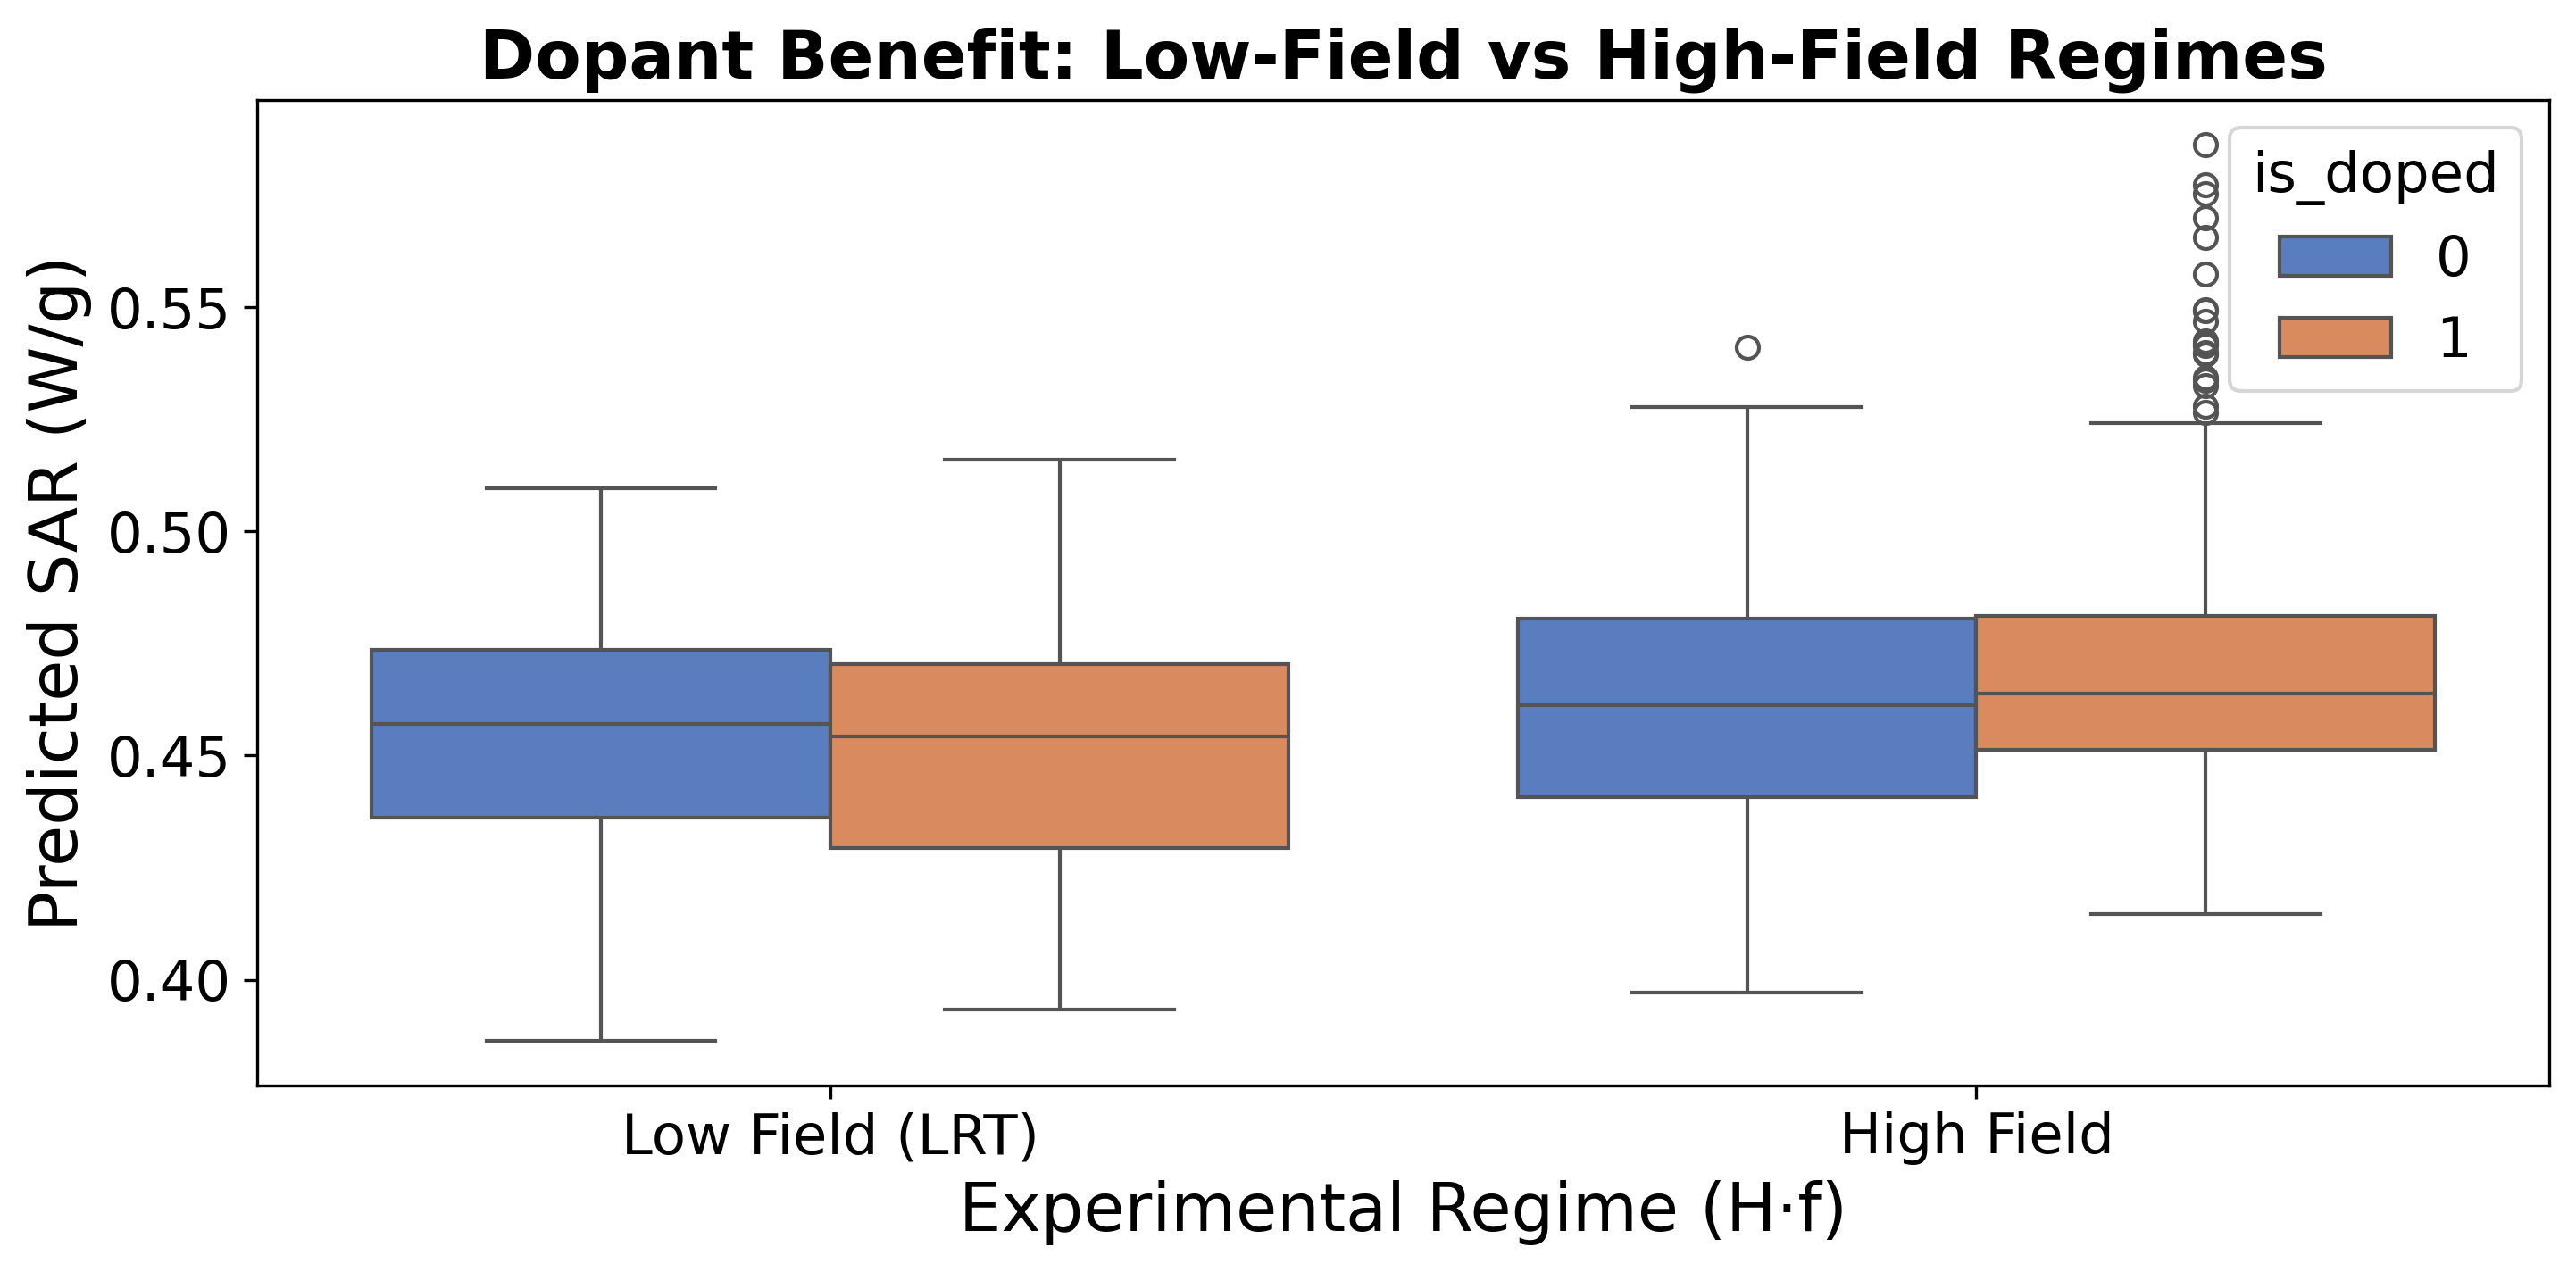

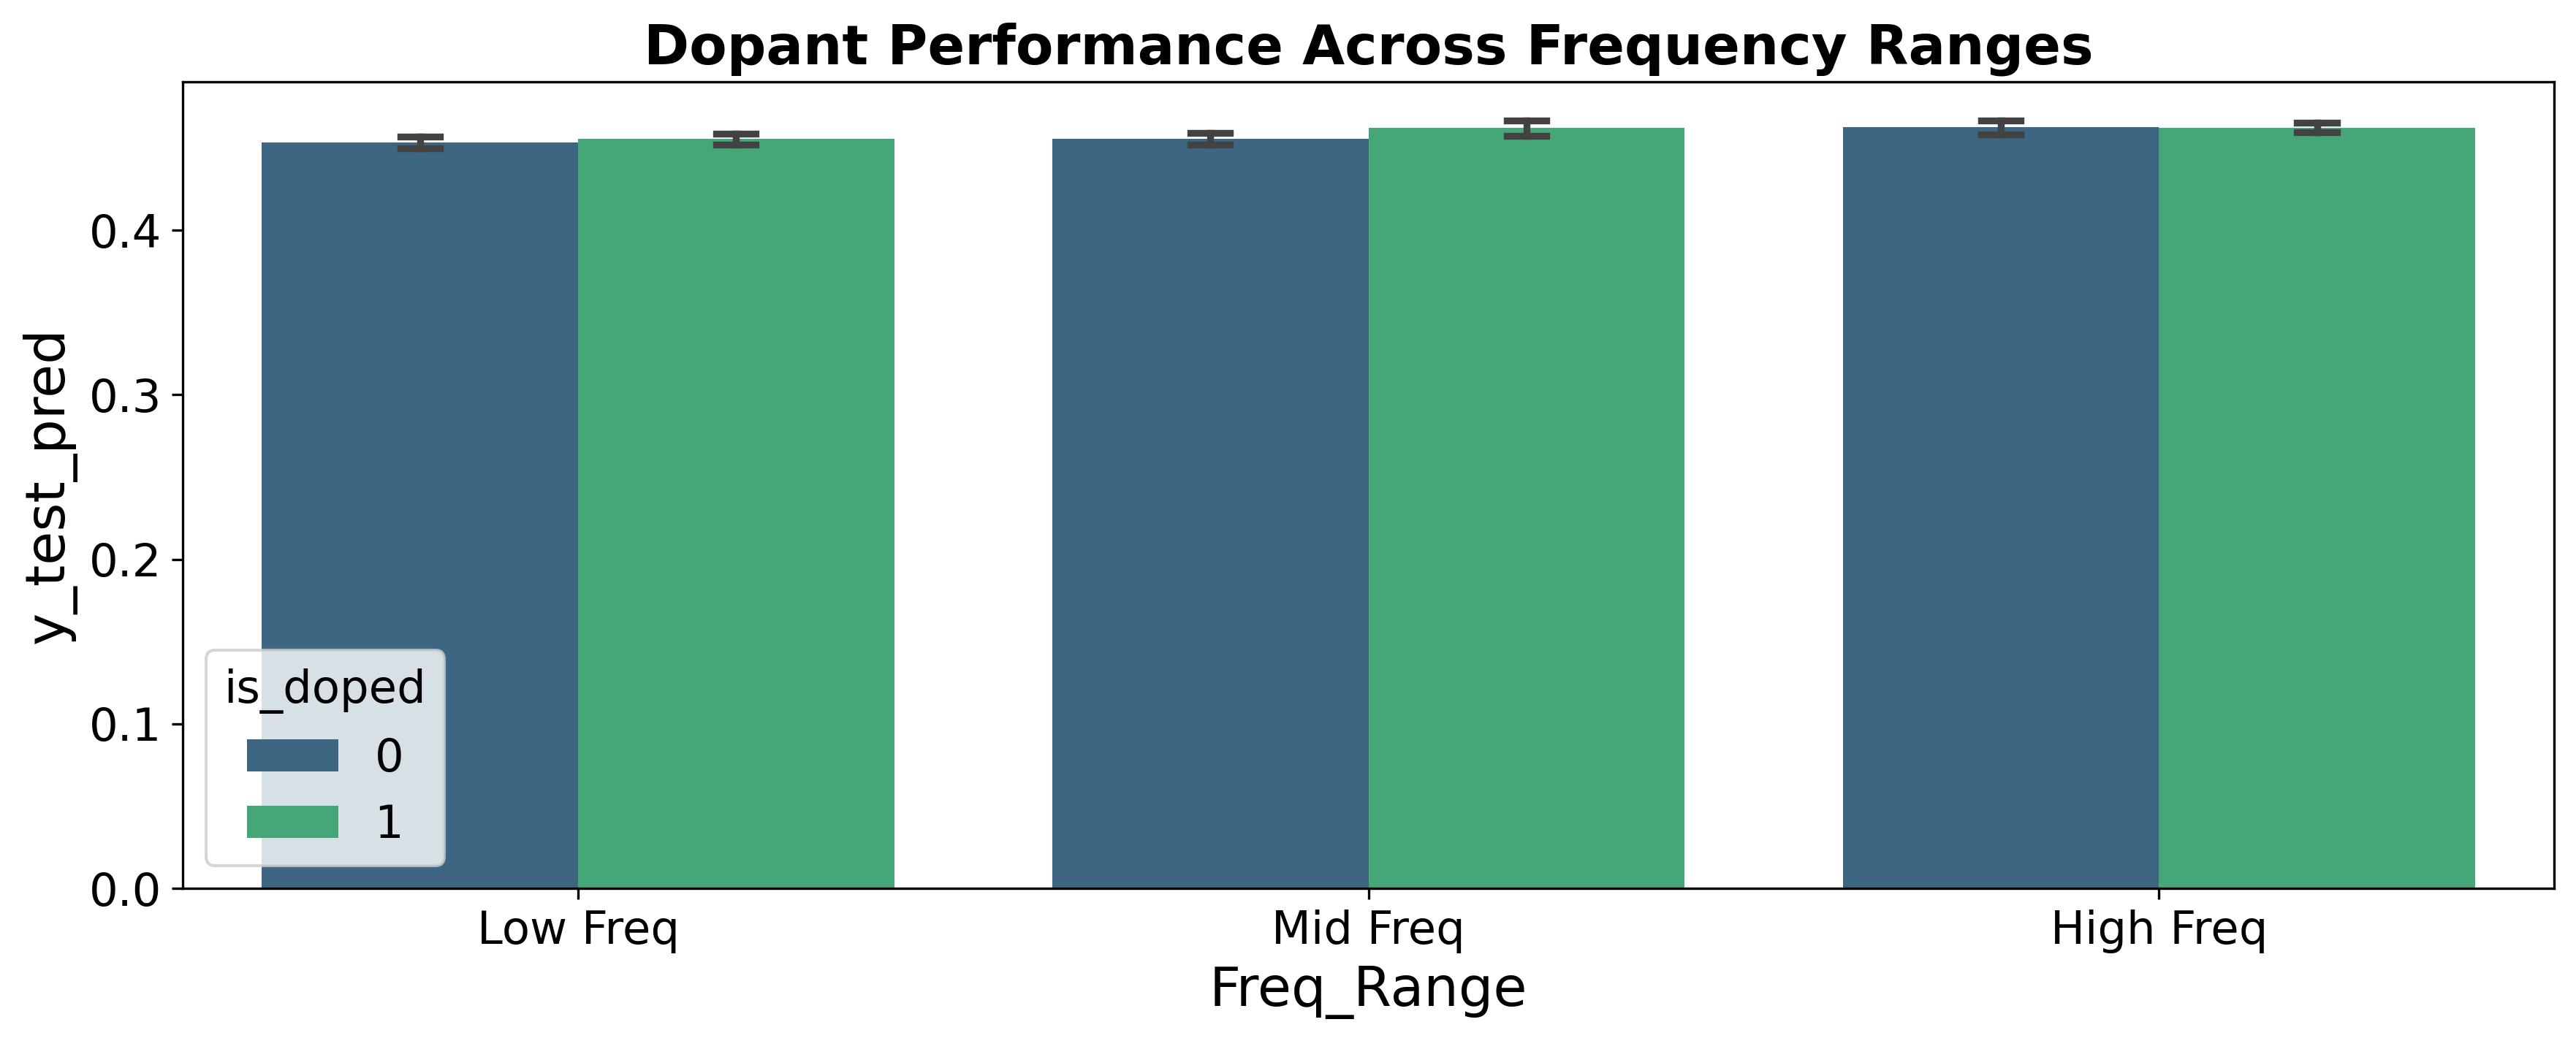

In [63]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df_raw, x='lrt', y='y_test_pred',
            hue='is_doped', palette='muted')
plt.title('Dopant Benefit: Low-Field vs High-Field Regimes', fontweight='bold')
plt.xlabel('Experimental Regime (H·f)')
plt.ylabel('Predicted SAR (W/g)')
plt.tight_layout()
plt.savefig('dopant_benefit.svg', dpi=800,bbox_inches = 'tight')
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=train_df_raw, x='Freq_Range', y='y_test_pred',
            hue='is_doped', palette='viridis', capsize=0.1)
plt.title('Dopant Performance Across Frequency Ranges', fontweight='bold')
plt.tight_layout()
plt.savefig('dopant_freq_range.svg', dpi=800,bbox_inches = 'tight')
plt.show()

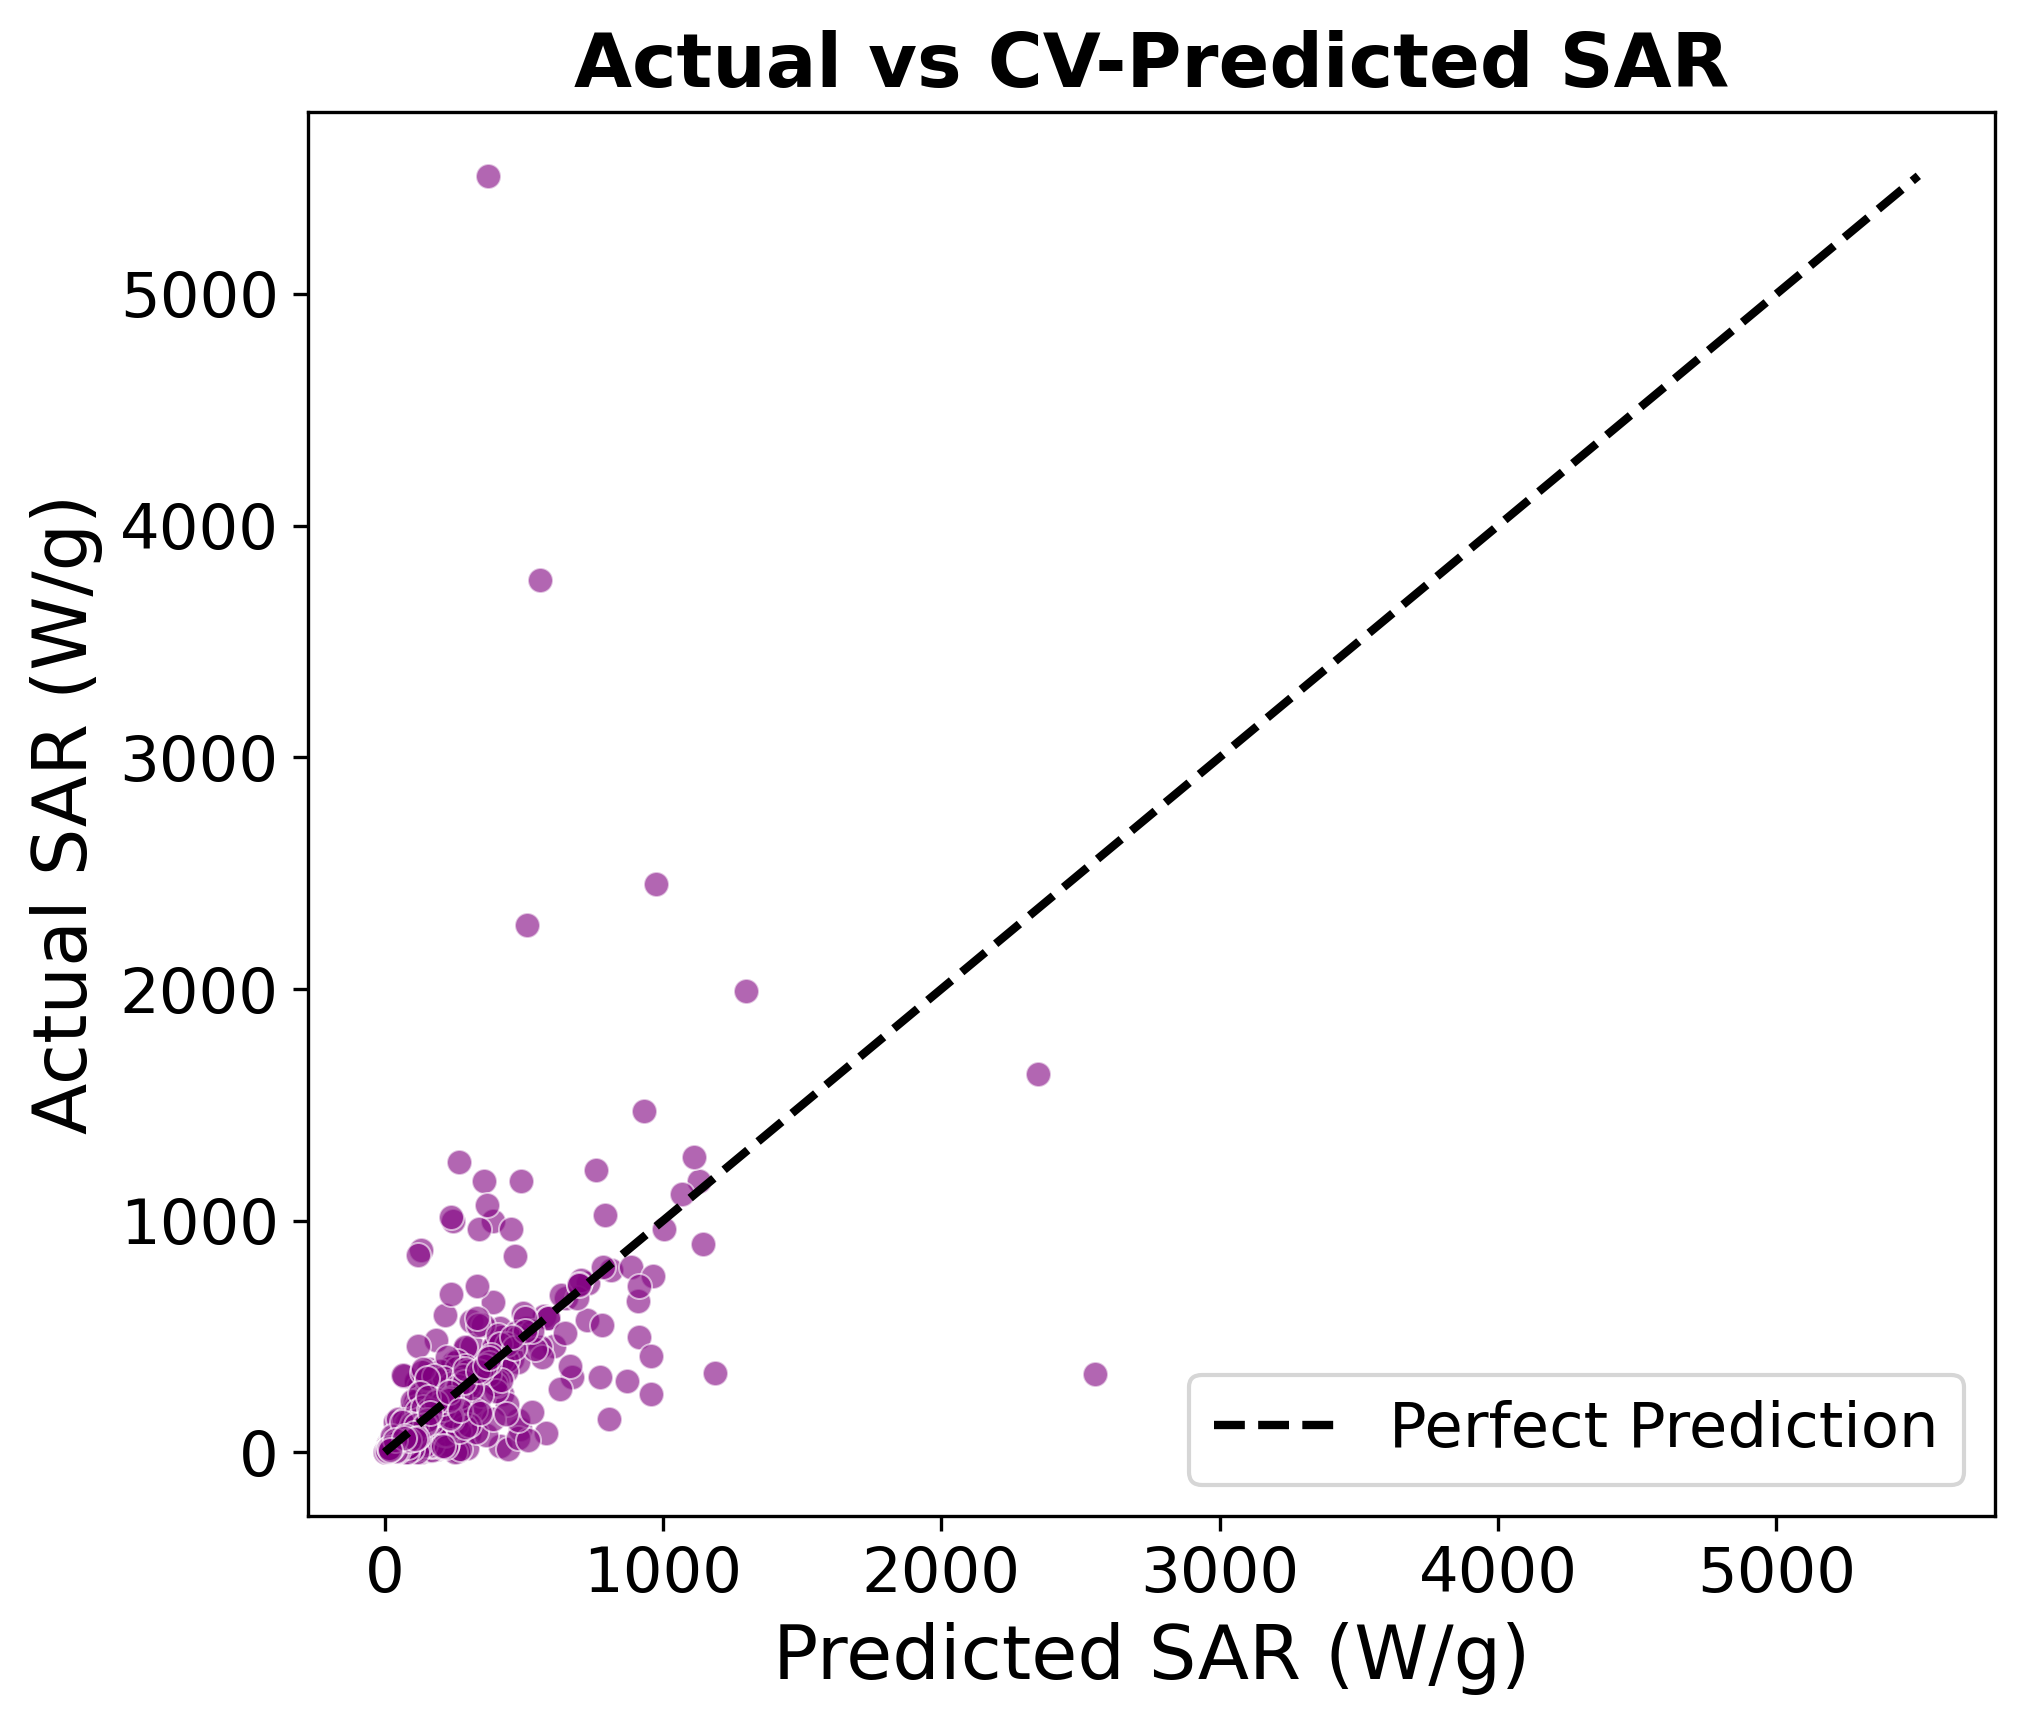

In [64]:
cv_preds = cross_val_predict(model, X, y, cv=5)
train_df_raw['CV_Predicted'] = cv_preds
train_df_raw['Residual']     = y.values - cv_preds

# A: Actual vs CV Predicted
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=train_df_raw, x='CV_Predicted', y=target_col,
                alpha=0.6, color='purple', ax=ax)
ax.plot([y.min(), y.max()], [y.min(), y.max()],
        'k--', lw=2, label='Perfect Prediction')
ax.set_title('Actual vs CV-Predicted SAR', fontweight='bold')
ax.set_xlabel('Predicted SAR (W/g)')
ax.set_ylabel('Actual SAR (W/g)')
ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.svg', dpi=800,bbox_inches = 'tight')
plt.show()

In [65]:
# # # B: Residuals vs core width  |  C: Residuals vs Ms
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for ax, xcol, color, xlabel in [
#     (axes[0], 'f_avg_core_width_nm', 'teal', 'Average Core Width (nm)'),
#     (axes[1], 'f_Ms_emu_g_MNP',      'blue', 'Ms (emu/g)'),
# ]:
#     sns.scatterplot(data=train_df_raw, x=xcol, y='Residual',
#                     alpha=0.6, color=color, ax=ax)
#    dpi=800,bbox_inches = 'tight'line(0, color='red', # linestyle='--', lw=2)
#     ax.set_xlabel(xlabel)
#     ax.set_ylabel('Residual (A# ctual − Predicted)')

# axes[0].set_title('Residuals vs Core Width# ', fontweight='bold')
# axes[1].set_title('Residuals vs Saturation Magnetisation'# , fontweight='bold'# )

# plt.tight_layout()
# plt.savefig('repngualdpi=800,b# box_inches = 'tight'operties.svg', dpi=800,bbox_inches = 'tight')
# plt.show()

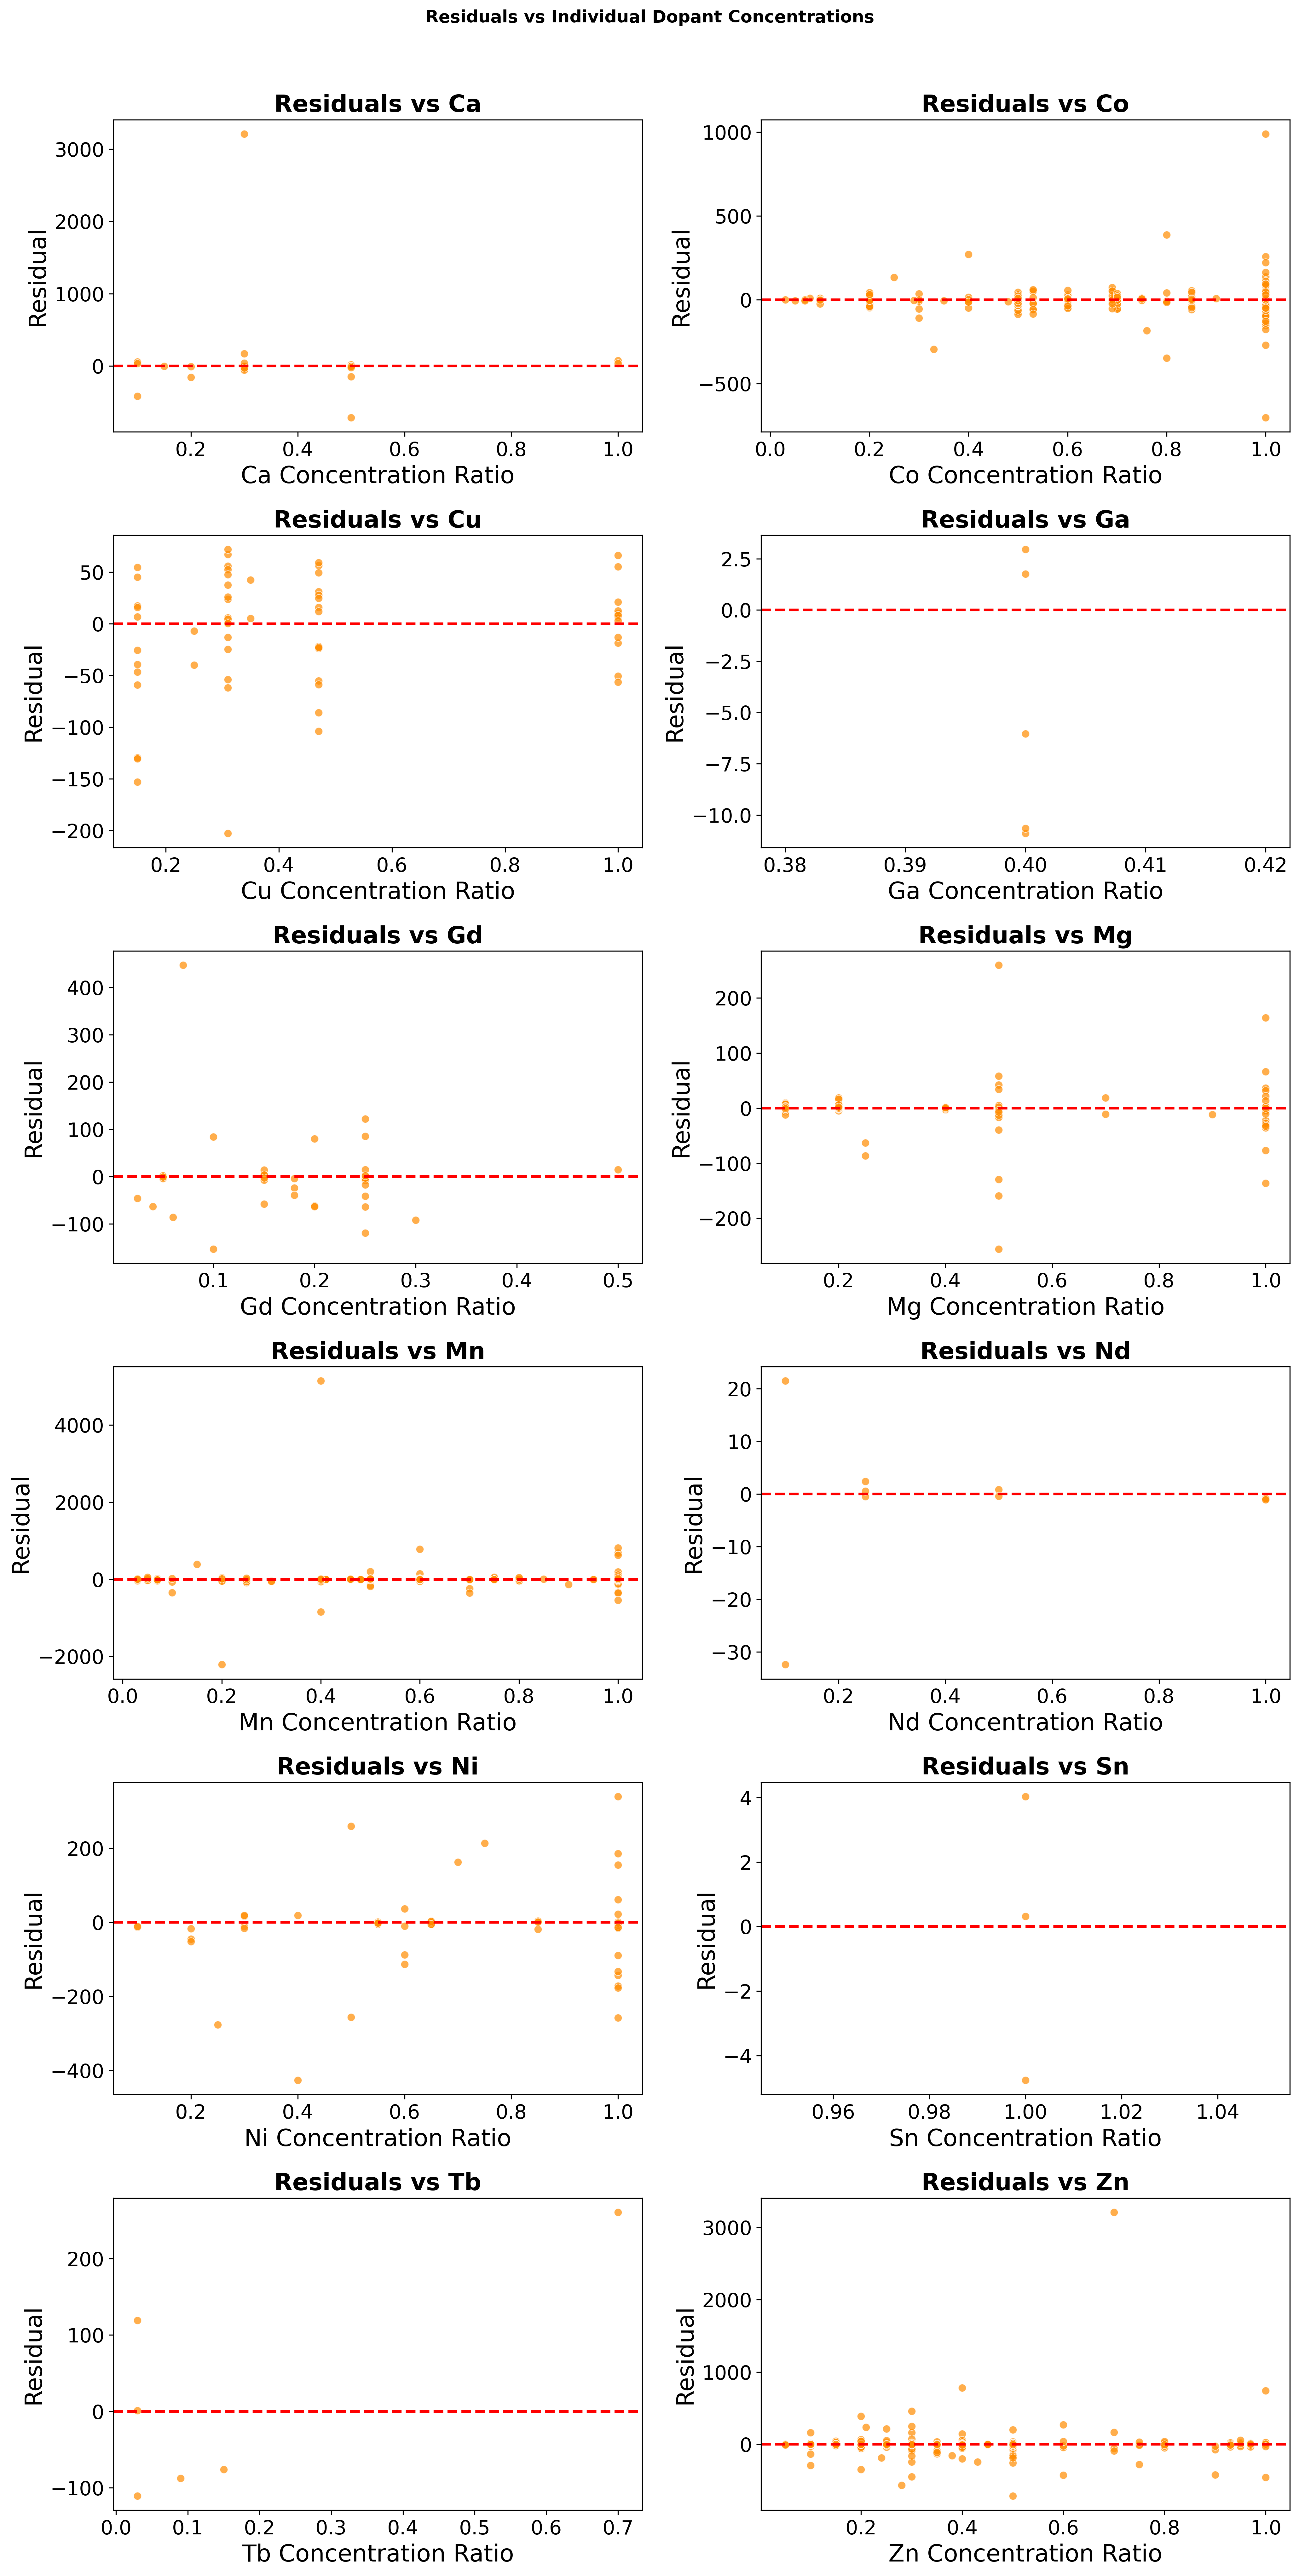

Top-10% worst predictions:
  Mean Core Width : 24.74 nm  (global: 15.61 nm)
  Mean Ms         : 69.72 emu/g  (global: 56.77 emu/g)


In [66]:
# D: Residuals vs each dopant concentration
valid_dopants = [c for c in dopant_cols if (train_df_raw[c] > 0).sum() >= 3]
n_rows_d = int(np.ceil(len(valid_dopants) / 2))

fig, axes = plt.subplots(n_rows_d, 2, figsize=(14, n_rows_d * 4.5))
axes = np.array(axes).flatten()

for i, dc in enumerate(valid_dopants):
    ax = axes[i]
    sub = train_df_raw[train_df_raw[dc] > 0]
    sns.scatterplot(data=sub, x=dc, y='Residual', alpha=0.7, color='darkorange', ax=ax)
    ax.axhline(0, color='red', linestyle='--', lw=2)
    name = dc.replace('_comp', '')
    ax.set_title(f'Residuals vs {name}', fontweight='bold')
    ax.set_xlabel(f'{name} Concentration Ratio')
    ax.set_ylabel('Residual')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Residuals vs Individual Dopant Concentrations', y=1.01,
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('residuals_vs_dopants.svg', dpi=800, bbox_inches='tight')
plt.show()

err_thresh = train_df_raw['Residual'].abs().quantile(0.90)
high_err   = train_df_raw[train_df_raw['Residual'].abs() >= err_thresh]
print(f"Top-10% worst predictions:")
print(f"  Mean Core Width : {high_err['f_avg_core_width_nm'].mean():.2f} nm  "      f"(global: {train_df_raw['f_avg_core_width_nm'].mean():.2f} nm)")
print(f"  Mean Ms         : {high_err['f_Ms_emu_g_MNP'].mean():.2f} emu/g  "      f"(global: {train_df_raw['f_Ms_emu_g_MNP'].mean():.2f} emu/g)")

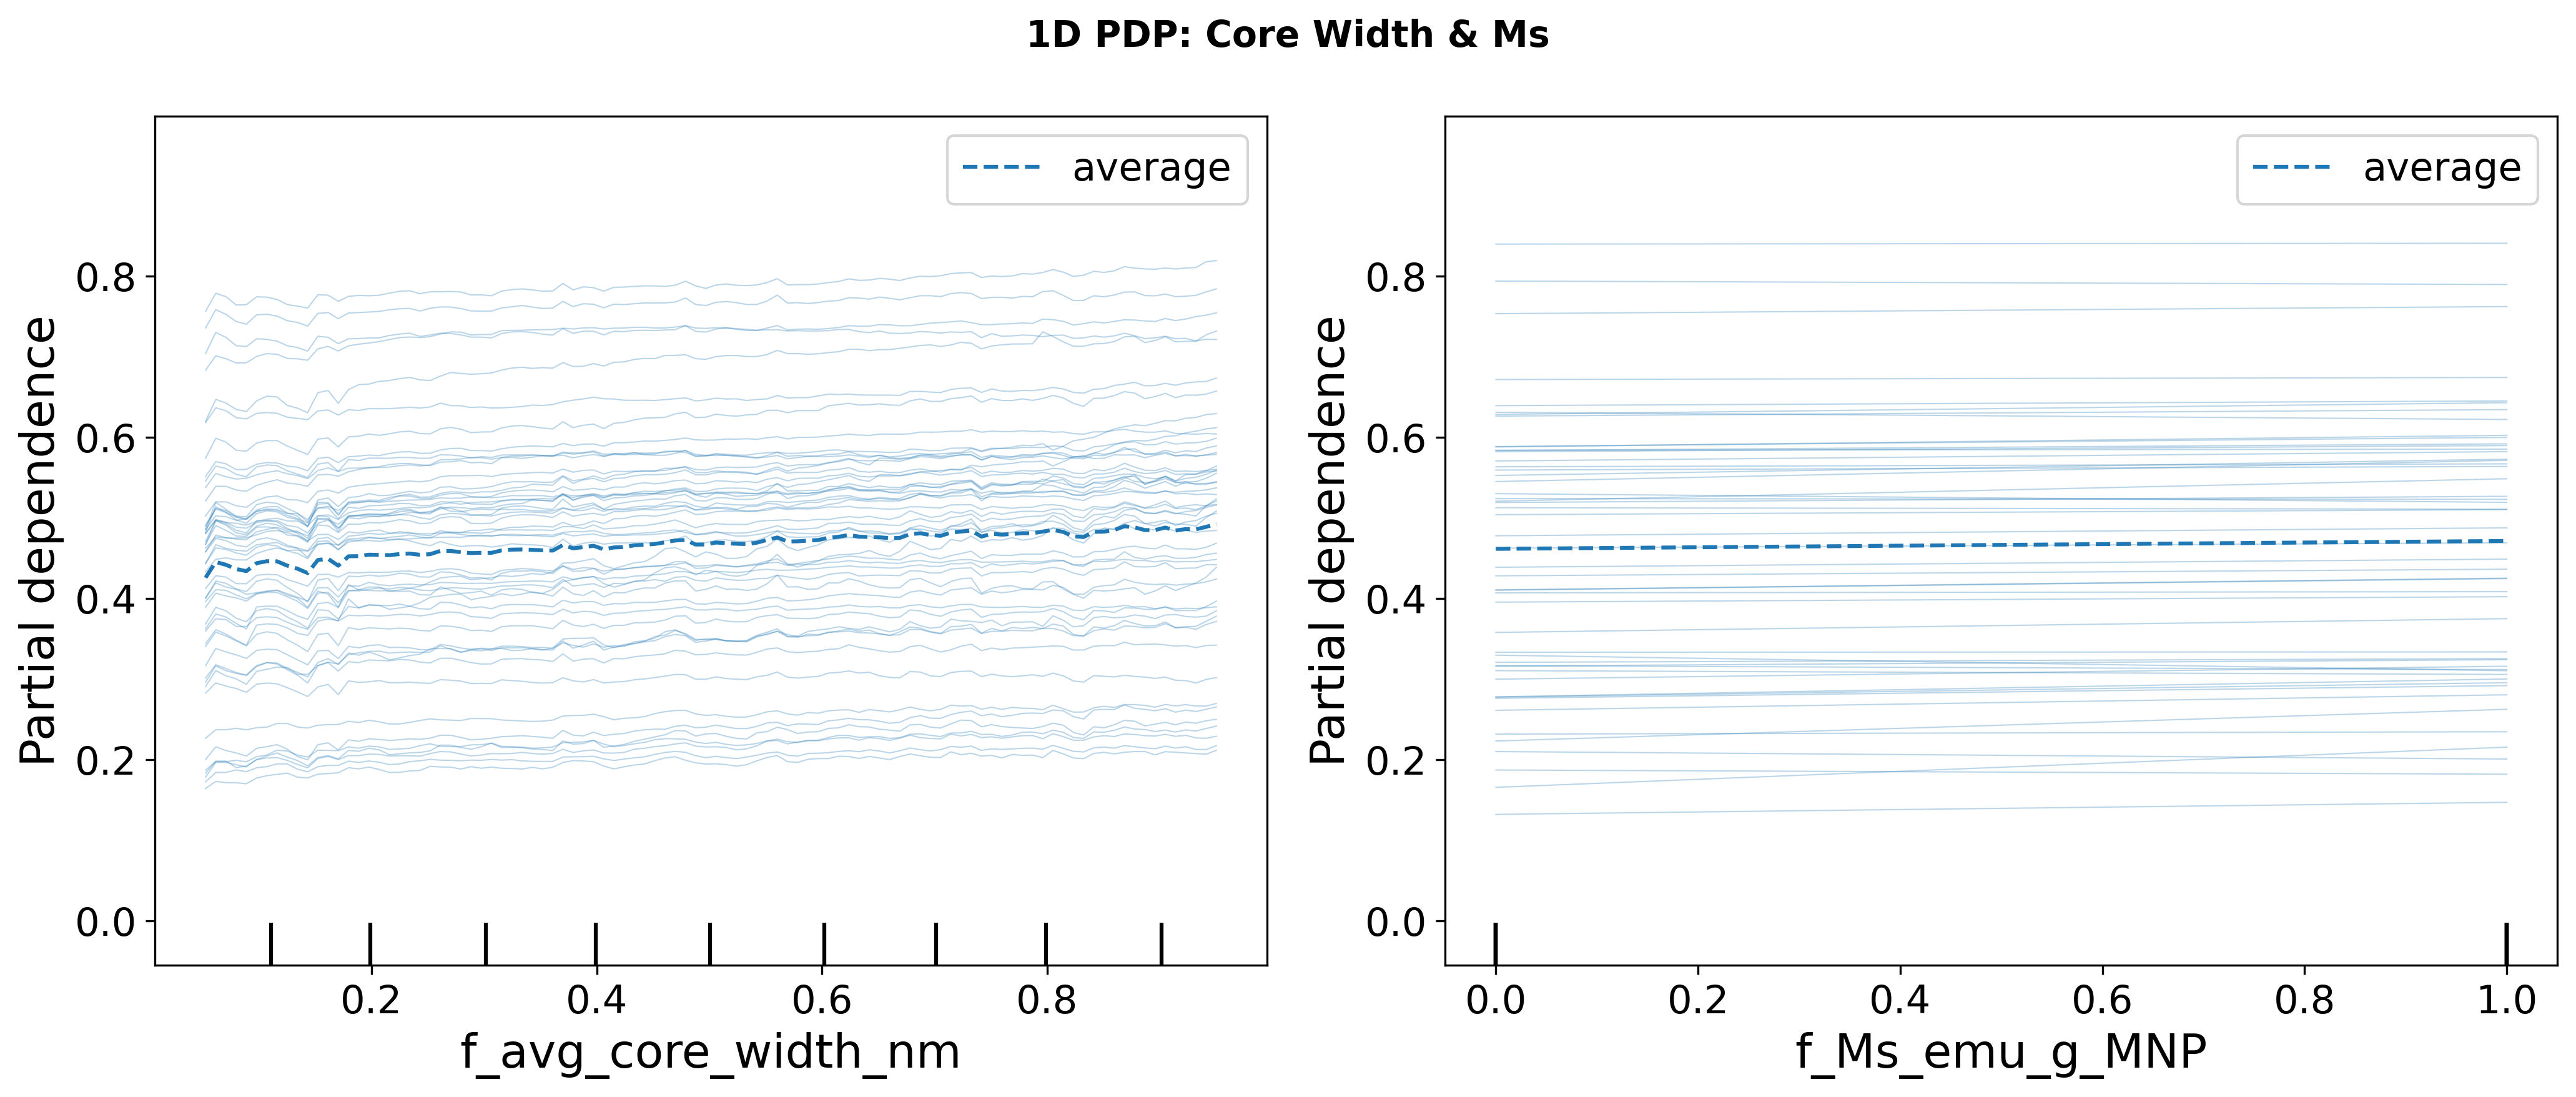

In [67]:
X_pdp = pd.DataFrame(x_train_scaled, columns=x_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
PartialDependenceDisplay.from_estimator(
    model, X_pdp,
    features=['f_avg_core_width_nm', 'f_Ms_emu_g_MNP'],
    kind='both', subsample=50, ax=axes,
)
plt.suptitle('1D PDP: Core Width & Ms', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pdp_1d.svg', dpi=800,bbox_inches = 'tight')
plt.show()

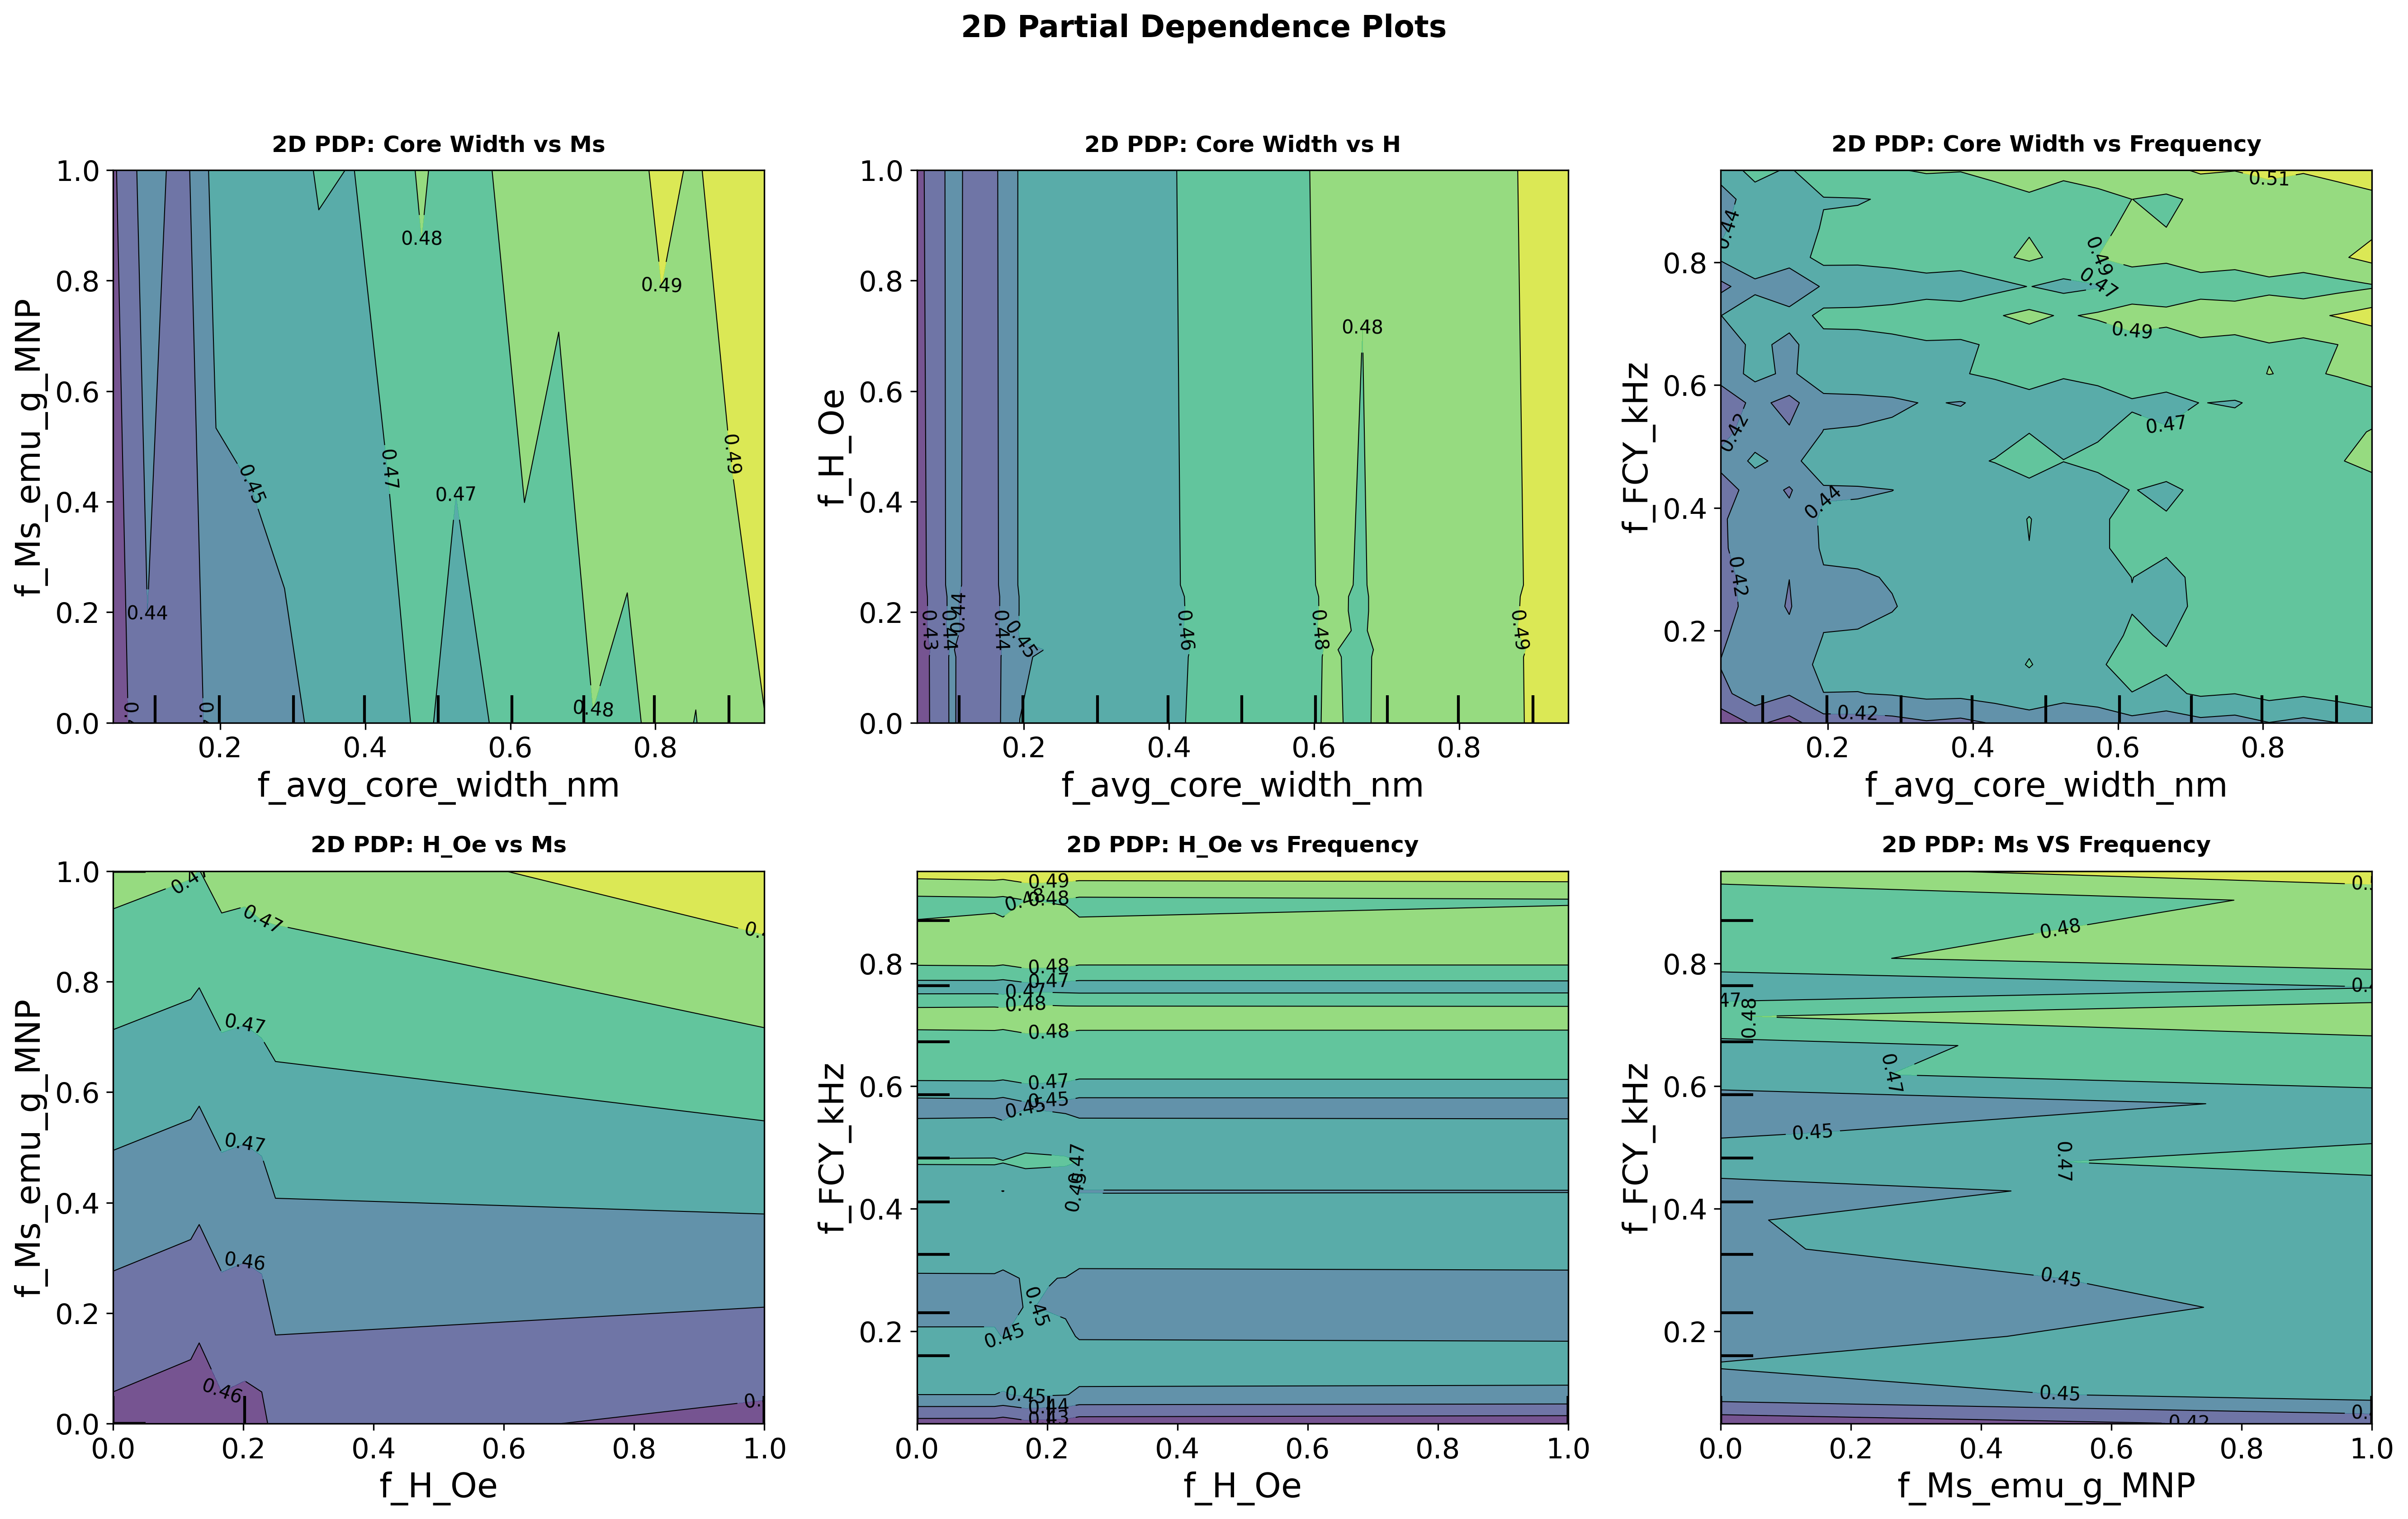

In [68]:
pairs = [
    ('f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'Core Width vs Ms'),
    ('f_avg_core_width_nm', 'f_H_Oe',          'Core Width vs H'),
    ('f_avg_core_width_nm', 'f_FCY_kHz',       'Core Width vs Frequency'),
    ('f_H_Oe',              'f_Ms_emu_g_MNP', 'H_Oe vs Ms'),
    ('f_H_Oe',              'f_FCY_kHz',       'H_Oe vs Frequency'),
     ('f_Ms_emu_g_MNP',  'f_FCY_kHz' , 'Ms VS Frequency')
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes_flat = axes.flatten()

for idx, (feat_a, feat_b, title) in enumerate(pairs):
    ax = axes_flat[idx]

    try:
        PartialDependenceDisplay.from_estimator(
            model,
            X_pdp,
            features=[(feat_a, feat_b)],
            kind='average',
            ax=ax,
            grid_resolution=20
        )
        ax.set_title(f'2D PDP: {title}', fontsize=12, fontweight='bold', pad=10)

    except ValueError as e:
        print(f"Skipping plot for ({feat_a}, {feat_b}) due to error: {e}")
        ax.set_visible(False)

if len(pairs) < len(axes_flat):
    for unused_ax in axes_flat[len(pairs):]:
        fig.delaxes(unused_ax)

plt.suptitle('2D Partial Dependence Plots', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

plt.savefig('pdp_2d_all_pairs_subplot.svg', dpi=800, bbox_inches='tight')
plt.show()

In [71]:
OPT_VARS = [
    "f_avg_core_width_nm",
    "f_Ms_emu_g_MNP",
    "f_Hc_Oe",
    "f_H_Oe",
    "f_FCY_kHz",
    "Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp","Mg_comp","Mn_comp"
]

BOUNDS = [
    (5.0, 30.0),
    (60.0, 150.0),
    (0.0, 100.0),
    (5.0, 300.0),
    (100.0, 500.0),
    (0.05, 0.20),
    (0.05, 0.20),
    (0.05, 0.20),
    (0.05, 0.20),
    (0.05, 0.20),
    (0.05, 0.20),
    (0.05, 0.20)
]

DIRECTION_WEIGHTS = {
    "f_avg_core_width_nm": -1.0,
    "f_Hc_Oe": -1.0,
    "f_FCY_kHz": -1.0,
    "f_Ms_emu_g_MNP": 1.0,
    "f_H_Oe": 1.0,
}

TARGET_WEIGHT = 15.0
SAR_SCALE = 2000.0
DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp", "Fe_comp","Mg_comp","Mn_comp"]
MAX_DOPANT_SUM = 3.0
LRT_HF_LIMIT = 5.0e9
OE_TO_A_M = 79.577
CONSTRAINT_PENALTY = 50.0

N_CANDIDATES = 20
DIVERSITY_RADIUS = 0.5
DIVERSITY_LAMBDA = 1.0
POPSIZE = 20
MAXITER = 150
RANDOM_STATE = 42

OPT_IDX = {name: i for i, name in enumerate(OPT_VARS)}
H_IDX = OPT_IDX["f_H_Oe"]
F_IDX = OPT_IDX["f_FCY_kHz"]
DOPANT_IDXS = [OPT_IDX[c] for c in DOPANT_COLS if c in OPT_IDX]
FREE_DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp","Mg_comp","Mn_comp"]
FE_COL = "Fe_comp"
FE_BOUNDS = (1.0, 3.0)
DOPANT_SUM_TARGET = 3.0
FREE_DOPANT_IDXS = [OPT_IDX[c] for c in FREE_DOPANT_COLS]

BOUNDS_ARR = np.array(BOUNDS)
BOUNDS_LO = BOUNDS_ARR[:, 0]
BOUNDS_HI = BOUNDS_ARR[:, 1]

def normalize(X):
    return (X - BOUNDS_LO) / (BOUNDS_HI - BOUNDS_LO + 1e-8)

def compute_fe_comp(X: np.ndarray) -> np.ndarray:
    return DOPANT_SUM_TARGET - X[:, FREE_DOPANT_IDXS].sum(axis=1)

def make_baseline_row(X_raw: pd.DataFrame, mode: str = "median") -> pd.DataFrame:
    row = X_raw.iloc[[0]].copy()
    for col in X_raw.columns:
        if pd.api.types.is_numeric_dtype(X_raw[col]):
            row[col] = X_raw[col].median() if mode == "median" else X_raw[col].iloc[0]
        else:
            row[col] = X_raw[col].mode().iloc[0] if mode == "median" else X_raw[col].iloc[0]
    return row

def batch_predict_sar(X: np.ndarray, model, transf, y_scaler, baseline_row_raw: pd.DataFrame, feature_names, numeric_cols, opt_vars=OPT_VARS) -> np.ndarray:
    n = X.shape[0]
    batch = pd.concat([baseline_row_raw]*n, ignore_index=True)
    for j, name in enumerate(opt_vars):
        batch[name] = X[:, j]

    batch[FE_COL] = compute_fe_comp(X)
    batch[numeric_cols] = transf.transform(batch[numeric_cols])

    y_model = model.predict(batch[feature_names])
    y_log = y_scaler.inverse_transform(y_model.reshape(-1, 1)).flatten()
    return np.expm1(y_log)

def objective_vectorized(X_T, model, transf, y_scaler, baseline_row_raw, feature_names, numeric_cols, penalized_points, debug=False):
    X = X_T.T
    n = X.shape[0]
    X_norm = normalize(X)

    sar = batch_predict_sar(X, model, transf, y_scaler, baseline_row_raw, feature_names, numeric_cols)

    raw_structural_score = np.zeros(n)
    for name, weight in DIRECTION_WEIGHTS.items():
        i = OPT_IDX[name]
        raw_structural_score += -weight * X_norm[:, i]
    raw_structural_score /= len(DIRECTION_WEIGHTS)

    raw_sar_score = -TARGET_WEIGHT * (sar / SAR_SCALE)

    h_am = X[:, H_IDX] * OE_TO_A_M
    f_hz = X[:, F_IDX] * 1000.0
    hf_violation = np.maximum(0.0, (h_am * f_hz) - LRT_HF_LIMIT) / LRT_HF_LIMIT

    fe_comp = compute_fe_comp(X)
    fe_lo, fe_hi = FE_BOUNDS
    fe_violation = (np.maximum(0.0, fe_lo - fe_comp) + np.maximum(0.0, fe_comp - fe_hi)) / (fe_hi - fe_lo)

    penalty = CONSTRAINT_PENALTY * (hf_violation + fe_violation)

    score = raw_structural_score + raw_sar_score + penalty

    diversity_term = np.zeros(n)
    if penalized_points:
        P = np.array(penalized_points)
        P_norm = normalize(P)
        dists = cdist(X_norm, P_norm)
        proximity = np.exp(-(dists ** 2) / (2 * DIVERSITY_RADIUS ** 2)).sum(axis=1)
        diversity_term = DIVERSITY_LAMBDA * proximity
        score = score + diversity_term

    if debug:
        print(f"  structural: mean={raw_structural_score.mean():+.3f} | "
              f"sar: mean={raw_sar_score.mean():+.3f} | "
              f"hf_pen: mean={hf_violation.mean():+.3f} | "
              f"fe_pen: mean={fe_violation.mean():+.3f} | "
              f"diversity: mean={diversity_term.mean():+.3f}")

    return score

def make_bounds_for_mask(active_names, base_bounds=BOUNDS):
    bounds = list(base_bounds)
    for name in FREE_DOPANT_COLS:
        i = OPT_IDX[name]
        if name in active_names:
            bounds[i] = base_bounds[i]
        else:
            bounds[i] = (0.0, 0.0)
    return bounds

def optimize_for_subset(active_names, model, transf, y_scaler, feature_names, numeric_cols, baseline_row_raw, n_candidates=N_CANDIDATES, seed_offset=5):
    bounds = make_bounds_for_mask(active_names)
    rows = []
    penalized_points = []

    for i in range(n_candidates):
        history = []
        Seed=RANDOM_STATE + seed_offset * i
        def callback_func(xk, convergence):
            val = objective_vectorized(xk.reshape(-1, 1), model, transf, y_scaler, baseline_row_raw, feature_names, numeric_cols, penalized_points)[0]
            history.append(val)

        result = differential_evolution(
            objective_vectorized,
            bounds=bounds,
            args=(model, transf, y_scaler, baseline_row_raw, feature_names, numeric_cols, penalized_points),
            vectorized=True,
            updating="deferred",
            popsize=POPSIZE,
            maxiter=MAXITER,
            tol=1e-7,
            mutation=(0.4, 1.0),
            recombination=0.7,
            polish=False,
            seed=Seed,
            callback=callback_func
        )
        best_x = result.x
        penalized_points.append(best_x)

        pred_sar = batch_predict_sar(
            best_x.reshape(1, -1), model, transf, y_scaler,
            baseline_row_raw, feature_names, numeric_cols
        )[0]

        fe_comp = float(compute_fe_comp(best_x.reshape(1, -1))[0])
        dopant_sum = float(best_x[FREE_DOPANT_IDXS].sum() + fe_comp)
        hf_product = float(best_x[H_IDX] * OE_TO_A_M * best_x[F_IDX] * 1000.0)
        fe_ok = FE_BOUNDS[0] <= fe_comp <= FE_BOUNDS[1]

        row = dict(zip(OPT_VARS, best_x))
        row["Fe_comp"] = fe_comp
        row["Predicted_SAR_W_g"] = pred_sar
        row["Dopant_Sum"] = dopant_sum
        row["Hf_product"] = hf_product
        row["Active_Dopants"] = "+".join(active_names)
        row["Constraint_Satisfied"] = bool(hf_product <= LRT_HF_LIMIT and fe_ok)
        row["Optimization_History"] = history
        row["Random Seed"] = Seed
        rows.append(row)

        print(f"Candidate {i+1:2d}/{n_candidates} [{'+'.join(active_names)}] | "
              f"Predicted SAR = {pred_sar:8.2f} W/g | "
              f"Dopant Sum = {dopant_sum:.4f} | Fe_comp = {fe_comp:.3f} "
              f"(bounds {FE_BOUNDS}) | "
              f"H*f = {hf_product:.3e} (limit {LRT_HF_LIMIT:.1e}) | "
              f"OK={row['Constraint_Satisfied']}")

    out = pd.DataFrame(rows).sort_values("Predicted_SAR_W_g", ascending=False).reset_index(drop=True)
    return out

def report_de_settings():
    print("\n" + "="*50)
    print("DIFFERENTIAL EVOLUTION (DE) SETTINGS:")
    print(f"  Population Size (popsize) : {POPSIZE}")
    print(f"  Max Generations (maxiter) : {MAXITER}")
    print("  Mutation (F) parameter    : (0.4, 1.0)")
    print("  Recombination (crossover) : 0.7")
    print("  Stopping Criterion (tol)  : 1e-7")
    print("  Updating Strategy         : deferred")
    print("  Polish                    : False")
    print("="*50 + "\n")

def plot_convergence_curve(history, candidate_name):
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(history) + 1), history, marker='o', linestyle='-', markersize=4, color='b')
    plt.title(f'Differential Evolution Convergence\n(Best Overall Candidate: {candidate_name})')
    plt.xlabel('Generation')
    plt.ylabel('Objective Function Value (Minimization)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('optimaization_convergence_plot_retro.svg')
    plt.show()

def optimize_across_dopant_subsets(model, transf, y_scaler, feature_names, numeric_cols, baseline_row_raw, subset_sizes=(2, 3, 5), max_subsets_per_size=8, n_candidates_per_subset=3):
    report_de_settings()

    all_results = []
    seed_offset = 5
    random.seed(RANDOM_STATE)

    for size in subset_sizes:
        subsets = list(combinations(FREE_DOPANT_COLS, size))
        if len(subsets) > max_subsets_per_size:
            subsets = random.sample(subsets, max_subsets_per_size)

        for active_names in subsets:
            print(f"\n--- Optimizing subset: {'+'.join(active_names)} ({size} active dopant(s) + Fe) ---")
            df = optimize_for_subset(list(active_names), model, transf, y_scaler, feature_names, numeric_cols, baseline_row_raw, n_candidates_per_subset, seed_offset)
            all_results.append(df)
            seed_offset += n_candidates_per_subset

    out = pd.concat(all_results, ignore_index=True)
    out = out.sort_values("Predicted_SAR_W_g", ascending=False).reset_index(drop=True)

    if not out.empty and "Optimization_History" in out.columns:
        best_history = out.iloc[0]["Optimization_History"]
        best_name = out.iloc[0]["Active_Dopants"]
        plot_convergence_curve(best_history, best_name)
        out = out.drop(columns=["Optimization_History"])

    return out

In [ ]:
baseline_row = make_baseline_row(x_train, mode="median")
feature_names = x_train.columns.tolist()

top20 = optimize_across_dopant_subsets(
    model=model,
    transf=transf,
    y_scaler=scaler,
    feature_names=feature_names,
    numeric_cols=numeric_cols,
    baseline_row_raw=baseline_row,
    subset_sizes=(2,3,4,5,6),
    max_subsets_per_size=10,
    n_candidates_per_subset=3,
)


DIFFERENTIAL EVOLUTION (DE) SETTINGS:
  Population Size (popsize) : 20
  Max Generations (maxiter) : 150
  Mutation (F) parameter    : (0.4, 1.0)
  Recombination (crossover) : 0.7
  Stopping Criterion (tol)  : 1e-7
  Updating Strategy         : deferred
  Polish                    : False


--- Optimizing subset: Mg_comp+Mn_comp (2 active dopant(s) + Fe) ---
Candidate  1/3 [Mg_comp+Mn_comp] | Predicted SAR =   161.54 W/g | Dopant Sum = 3.0000 | Fe_comp = 2.812 (bounds (1.0, 3.0)) | H*f = 4.877e+09 (limit 5.0e+09) | OK=True
Candidate  2/3 [Mg_comp+Mn_comp] | Predicted SAR =   159.14 W/g | Dopant Sum = 3.0000 | Fe_comp = 2.746 (bounds (1.0, 3.0)) | H*f = 4.924e+09 (limit 5.0e+09) | OK=True
Candidate  3/3 [Mg_comp+Mn_comp] | Predicted SAR =   158.75 W/g | Dopant Sum = 3.0000 | Fe_comp = 2.604 (bounds (1.0, 3.0)) | H*f = 4.965e+09 (limit 5.0e+09) | OK=True

--- Optimizing subset: Zn_comp+Ni_comp (2 active dopant(s) + Fe) ---
Candidate  1/3 [Zn_comp+Ni_comp] | Predicted SAR =   180.89 W/g 

In [ ]:
DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp", "Fe_comp", "Mn_comp","Mg_comp"]

def format_composition(row):
    parts = []
    for dopant in FREE_DOPANT_COLS:
        val = row[dopant]
        if val > 0:
            symbol = dopant.replace("_comp", "")
            parts.append(f"{symbol}{val:.2f}")
    parts.append(f"Fe{row['Fe_comp']:.2f}")
    return "".join(parts) + "O4"

top20["Composition"] = top20.apply(format_composition, axis=1)

cols_to_show = (OPT_VARS + ["Fe_comp", "Composition", "Predicted_SAR_W_g",
                             "Dopant_Sum", "Hf_product", "Constraint_Satisfied"])
print(top20[cols_to_show].round(3).to_string())

n_ok = int(top20["Constraint_Satisfied"].sum())
print(f"\n{n_ok}/{len(top20)} candidates satisfy the LRT safety limit and dopant-sum constraint.")

top20.to_excel("top_candidates_tabpfn_retro.xlsx", index=False)

In [ ]:
from google.colab import files
files.download('/content/top_candidates_tabpfn_retro.xlsx')

In [ ]:
best_group = 'Ni_comp+Mg_comp+Mn_comp'
df = pd.read_excel("top_candidates_tabpfn_retro.xlsx")
# 1. Filter the dataframe for only this specific dopant group
df_top = df[df['Active_Dopants'] == best_group].copy()

# 2. Extract the active elements plus Iron (Fe_comp)
elements_to_plot = best_group.split('+') + ['Fe_comp']
plot_data = df_top[elements_to_plot]

# 3. Melt the dataframe to format it for Seaborn (transforms columns into 'Element' and 'Value' rows)
melted_data = plot_data.melt(var_name='Element', value_name='Composition Fraction')

# 4. Generate the Visualization
plt.figure(figsize=(9, 6))

# Plot the mean as bars with standard deviation (error bars)
sns.barplot(
    x='Element',
    y='Composition Fraction',
    data=melted_data,
    capsize=0.1,           # Adds caps to the error bars
    color='lightsteelblue',
    edgecolor='black',
    errcolor='black',
    errorbar='sd'          # 'sd' calculates and displays standard deviation
)

# Overlay the 3 exact random seed readings as dots
sns.stripplot(
    x='Element',
    y='Composition Fraction',
    data=melted_data,
    color='darkred',
    alpha=0.8,
    jitter=0.05,           # Slight horizontal spread so overlapping dots are visible
    size=9,
    label='Individual Seed Readings'
)

# 5. Format titles and labels
plt.title(f'Compositional Variance Across Random Seeds\n(Optimal Group: {best_group})',
          fontsize=14, fontweight='bold')
plt.ylabel('Composition Fraction', fontsize=12, fontweight='bold')
plt.xlabel('Elemental Component', fontsize=12, fontweight='bold')

# Ensure the legend only shows once for the stripplot
handles, labels = plt.gca().get_legend_handles_labels()
if handles:
    plt.legend(handles[:1], labels[:1], loc='best')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("Random_seed_retro.svg")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

def calculate_applicability_domain(df_train, df_candidates, feature_cols, dopant_cols):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(df_train[feature_cols])
    X_candidates_scaled = scaler.transform(df_candidates[feature_cols])

    nn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    nn.fit(X_train_scaled)

    distances, indices = nn.kneighbors(X_candidates_scaled)
    df_candidates['Dist_to_Nearest_Train_Sample'] = distances.flatten()

    comp_scaler = StandardScaler()
    C_train_scaled = comp_scaler.fit_transform(df_train[dopant_cols])
    C_candidates_scaled = comp_scaler.transform(df_candidates[dopant_cols])

    nn_comp = NearestNeighbors(radius=0.5, metric='euclidean')
    nn_comp.fit(C_train_scaled)

    counts = []
    for i, candidate in enumerate(C_candidates_scaled):
        neighbors = nn_comp.radius_neighbors([candidate], return_distance=False)
        counts.append(len(neighbors[0]))

    df_candidates['Num_Similar_Train_Records'] = counts

    return df_candidates

In [ ]:
updated_candidates_df = calculate_applicability_domain(
    df_train=x_train,
    df_candidates=top20,
    feature_cols=OPT_VARS,
    dopant_cols=DOPANT_COLS
)

display_columns = ['Active_Dopants', 'Predicted_SAR_W_g', 'Dist_to_Nearest_Train_Sample', 'Num_Similar_Train_Records']
updated_candidates_df.to_excel("SIMILARITY_RETRO.xlsx")
print(updated_candidates_df[display_columns].head(10))